<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

<div align="center">
<h1 style="font-size: 48px; font-weight: 800; color: #2c3e50; margin-bottom: 5px; letter-spacing: -1px; text-transform: uppercase;">
Global Air Pollution
</h1>



<div style="margin-bottom: 30px;">
<p style="font-size: 18px; color: #5d6d7e; margin: 5px 0;">
<b>Module :</b> Visualisation des données &nbsp;|&nbsp; 
<b>Filière :</b> Big Data et Intelligence Artificielle
</p>
<p style="font-size: 18px; color: #5d6d7e; margin: 5px 0;">
<b>Encadré par :</b> Prof. Ikhlass Boukrouh
</p>
</div>

<hr style="border: 0; height: 1px; background: rgba(0,0,0,0.1); margin: 30px 0;">

<h2 style="font-size: 20px; color: #2c3e50; margin-bottom: 25px; font-weight: 600;">RÉALISÉ PAR :</h2>

<div style="display: flex; flex-wrap: wrap; justify-content: center; gap: 15px 40px; font-size: 16px; font-weight: 600; color: #5d6d7e; letter-spacing: 0.5px;">
<span>AL BAAZA ADNAN</span>
</div>

</div>
</div>


### Plan de Projet
- Netoyage de donnees
- Vusualisation Univariees
- Visualisation Bivariees
- Visualisation Mulitivariees
- Visualisation geospatiale
- Conclusion generale

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Netoyage des donnes </div>

In [2]:
# Importaion des biblioteques
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

# Iportation des donnes
df = pd.read_csv('global_air_pollution.csv')
display(df.head())
# Affichage de la forme du dataframe
print(df.shape)



,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


(23463, 12)


In [3]:
# valeurs manquantes
display(df.isnull().sum())

Country               427
City                    1
AQI Value               0
AQI Category            0
CO AQI Value            0
CO AQI Category         0
Ozone AQI Value         0
Ozone AQI Category      0
NO2 AQI Value           0
NO2 AQI Category        0
PM2.5 AQI Value         0
PM2.5 AQI Category      0
dtype: int64

In [4]:
# il exist une seule valeur manquante dans la colonne 'City' et 427 valeurs manquantes dans la colonne 'country'.
# Nous allons supprimer ces lignes.
df = df.dropna(subset=['City', 'Country'])

In [5]:
# voir est ce qui des valeurs anormales dans dans le dataframe
display(df.describe())

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
count,23035.000000,23035.000000,23035.000000,23035.000000,23035.000000
mean,72.344693,1.376254,35.233905,3.084741,68.883482
std,56.360992,1.844926,28.236613,5.281708,55.057396
min,6.000000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,1.000000,21.000000,0.000000,35.000000
50%,55.000000,1.000000,31.000000,1.000000,54.000000
75%,80.000000,1.000000,40.000000,4.000000,79.000000
max,500.000000,133.000000,235.000000,91.000000,500.000000


#### Les statistiques aux dessus montre qu'il n  y a pas de valeurs anormales dans le dataframe.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation Univariees
- Variable Quantitatives </div>

#### Commoncons par les variables quantitatives
Les variables quantitatives sont : 'AQI', PM2.5', 'NO2', 'CO', 'O3'.
Nous allons visualiser la distribution de ces variables à l'aide de :
- Histogramme
- Courbe de densité
- Boîte à moustaches (Boxplot)
- Diagramme en violon (Violin plot)
- Diagramme en points


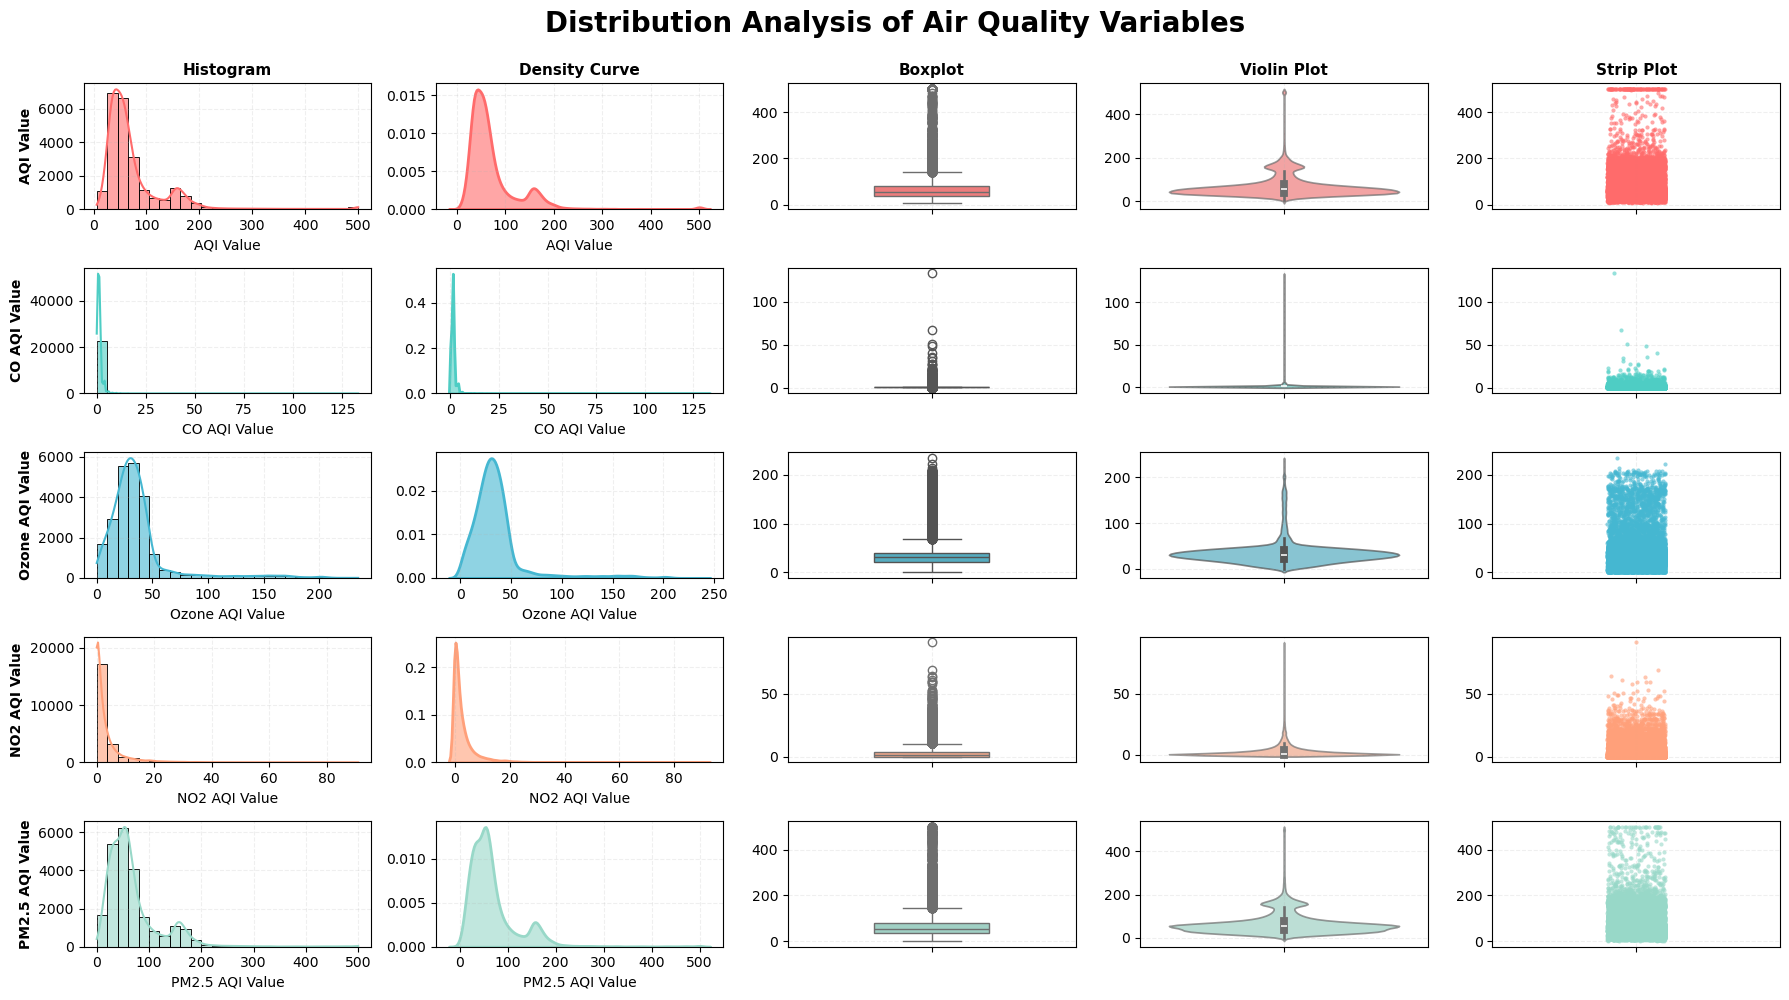

In [6]:
# Define quantitative variables from CSV
variables = ['AQI Value', 'CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']

# Define plot types labels
plot_types = ['Histogram', 'Density Curve', 'Boxplot', 'Violin Plot', 'Strip Plot']

# Create figure with subplots (5 variables × 5 plot types)
fig, axes = plt.subplots(5, 5, figsize=(18, 10))
fig.suptitle('Distribution Analysis of Air Quality Variables', fontsize=20, fontweight='bold', y=0.995)

# Define distinct colors for each variable
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']

# Populate the 5×5 grid
for i, var in enumerate(variables):
    for j in range(5):
        ax = axes[i, j]
        
        # Column 0: Histogram with KDE
        if j == 0:
            sns.histplot(data=df, x=var, kde=True, ax=ax, color=colors[i], alpha=0.6, bins=25)
            if i == 0:
                ax.set_title('Histogram', fontweight='bold', fontsize=11)
        
        # Column 1: Density Curve (KDE)
        elif j == 1:
            sns.kdeplot(data=df, x=var, ax=ax, color=colors[i], fill=True, alpha=0.6, linewidth=2)
            if i == 0:
                ax.set_title('Density Curve', fontweight='bold', fontsize=11)
        
        # Column 2: Boxplot
        elif j == 2:
            sns.boxplot(data=df, y=var, ax=ax, color=colors[i], width=0.4)
            if i == 0:
                ax.set_title('Boxplot', fontweight='bold', fontsize=11)
        
        # Column 3: Violin Plot
        elif j == 3:
            sns.violinplot(data=df, y=var, ax=ax, color=colors[i], alpha=0.7)
            if i == 0:
                ax.set_title('Violin Plot', fontweight='bold', fontsize=11)
        
        # Column 4: Strip Plot (Scatter with jitter)
        elif j == 4:
            sns.stripplot(data=df, y=var, ax=ax, color=colors[i], alpha=0.6, jitter=True, size=3)
            if i == 0:
                ax.set_title('Strip Plot', fontweight='bold', fontsize=11)
        
        # Set y-axis label only for the first column
        if j == 0:
            ax.set_ylabel(var, fontweight='bold', fontsize=10)
        else:
            ax.set_ylabel('')
        
        
        
        # Add subtle grid for better readability
        ax.grid(True, alpha=0.2, linestyle='--')


plt.tight_layout()
plt.show()



### 1. Interprétation - AQI Value

**Analyse de la distribution :**
- **Forme** : Asymétrie positive (positivement asymétrique)
- **Dispersion** : Dispersion modérée - les données sont assez bien distribuées, avec une concentration visible dans la plage basse à moyenne (0-150)
- **Observations** : La majorité des valeurs se concentrent à gauche (0-100), avec une très longue traîne vers la droite (jusqu'à +500). La distribution montre que la plupart des régions ont une qualité d'air moyenne, mais avec quelques valeurs extrêmes

**Décision possible :**
Les données présentent une asymétrie positive modérée. Pour l'analyse statistique, une transformation logarithmique ou une normalisation pourrait être envisagée. La qualité d'air varie considérablement entre les régions, mais reste généralement dans une plage acceptable.

### 2. Interprétation - CO AQI Value

**Analyse de la distribution :**
- **Forme** : Asymétrie positive extrême (très positivement asymétrique)
- **Dispersion** : Très basse dispersion - données hautement concentrées
- **Observations** : Les données sont extrêmement concentrées près de 0 (plus de 50 000 observations), avec une chute drastique après la première barre. Très peu de valeurs dépassent 25. Cette concentration extrême indique que le CO est très peu présent dans l'air dans la majorité des régions

**Décision possible :**
Le monoxyde de carbone est très peu dispersé dans l'air globalement. Les niveaux de CO restent extrêmement bas dans presque toutes les régions. Pas de préoccupation majeure concernant la dispersion du CO dans la qualité de l'air global.

### 3. Interprétation - Ozone AQI Value

**Analyse de la distribution :**
- **Forme** : Distribution approximativement symétrique (peu d'asymétrie)
- **Dispersion** : Bonne dispersion - les données sont bien réparties sur l'intervalle
- **Observations** : La distribution de l'ozone montre une forme quasi-normale avec un pic central autour de 30-40. Les données s'étendent régulièrement de 0 à 250+, sans concentration excessive. C'est la distribution la plus équilibrée parmi les 5 variables

**Décision possible :**
La distribution symétrique de l'ozone facilite l'analyse statistique classique. Les niveaux d'ozone varient régulièrement entre les régions, ce qui suggère des facteurs géographiques ou climatiques influencent sa présence. Les données sont adéquates pour des tests paramétriques.

### 4. Interprétation - NO2 AQI Value

**Analyse de la distribution :**
- **Forme** : Asymétrie positive très prononcée (fortement positivement asymétrique)
- **Dispersion** : Très basse dispersion - données hautement concentrées au bas de l'échelle
- **Observations** : Plus de 20 000 observations sont concentrées à 0-5, avec une décroissance extrêmement rapide. Les données ne dépassent pratiquement jamais 80. Le NO2 est très peu présent dans la majorité des régions monitorées

**Décision possible :**
Le dioxyde d'azote montre une concentration extrême aux niveaux bas. Similaire au CO, la plupart des régions ont des niveaux de NO2 très faibles. Il n'y a pas de problème de dispersion majeure du NO2 dans la pollution de l'air globale analysée.

### 5. Interprétation - PM2.5 AQI Value

**Analyse de la distribution :**
- **Forme** : Asymétrie positive (positivement asymétrique)
- **Dispersion** : Dispersion modérée - comparable à l'AQI Value avec de bons niveaux de variation
- **Observations** : La distribution des particules fines (PM2.5) montre une concentration principale entre 0-150, avec une longue traîne jusqu'à 500. Les deux premières barres de l'histogramme contiennent la majorité des données (environ 6000 + 4000 observations). Les niveaux de PM2.5 varient significativement selon les régions

**Décision possible :**
Le PM2.5 présente une asymétrie positive modérée, similaire à l'AQI global. Les particules fines sont un polluant préoccupant dans certaines régions (longue traîne), tandis que d'autres régions restent relativement propres. Une stratégie de réduction ciblée sur les zones avec des niveaux élevés de PM2.5 serait pertinente.

---

### Résumé Comparatif des 5 Variables

| Variable | Asymétrie | Dispersion | Caractéristique Clé |
|----------|-----------|------------|----------------------|
| **AQI Value** | Positive modérée | Modérée | Distribution large, variations significatives |
| **CO AQI Value** | Positive extrême | Très basse | Concentré près de 0, peu dispersé |
| **Ozone AQI Value** | Quasi-symétrique | Bonne | Distribution équilibrée, parfaitem réparti |
| **NO2 AQI Value** | Positive extrême | Très basse | Concentré près de 0, peu présent |
| **PM2.5 AQI Value** | Positive modérée | Modérée | Distribution large, variations significatives |


<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation Univariees
- Variable Qualitatives </div>

#### Commoncons par les variables quantitatives
Les variables qualitatives sont : 'City',  'Country',  'AQI Category'.

Nous allons visualiser la distribution de ces variables à l'aide de :
- Diagramme en barres (vertical ou horizontal)
- Diagramme de Pareto
- Diagramme circulaire (en secteurs)


C:\Users\Thin\AppData\Local\Temp\ipykernel_17852\2469379044.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)


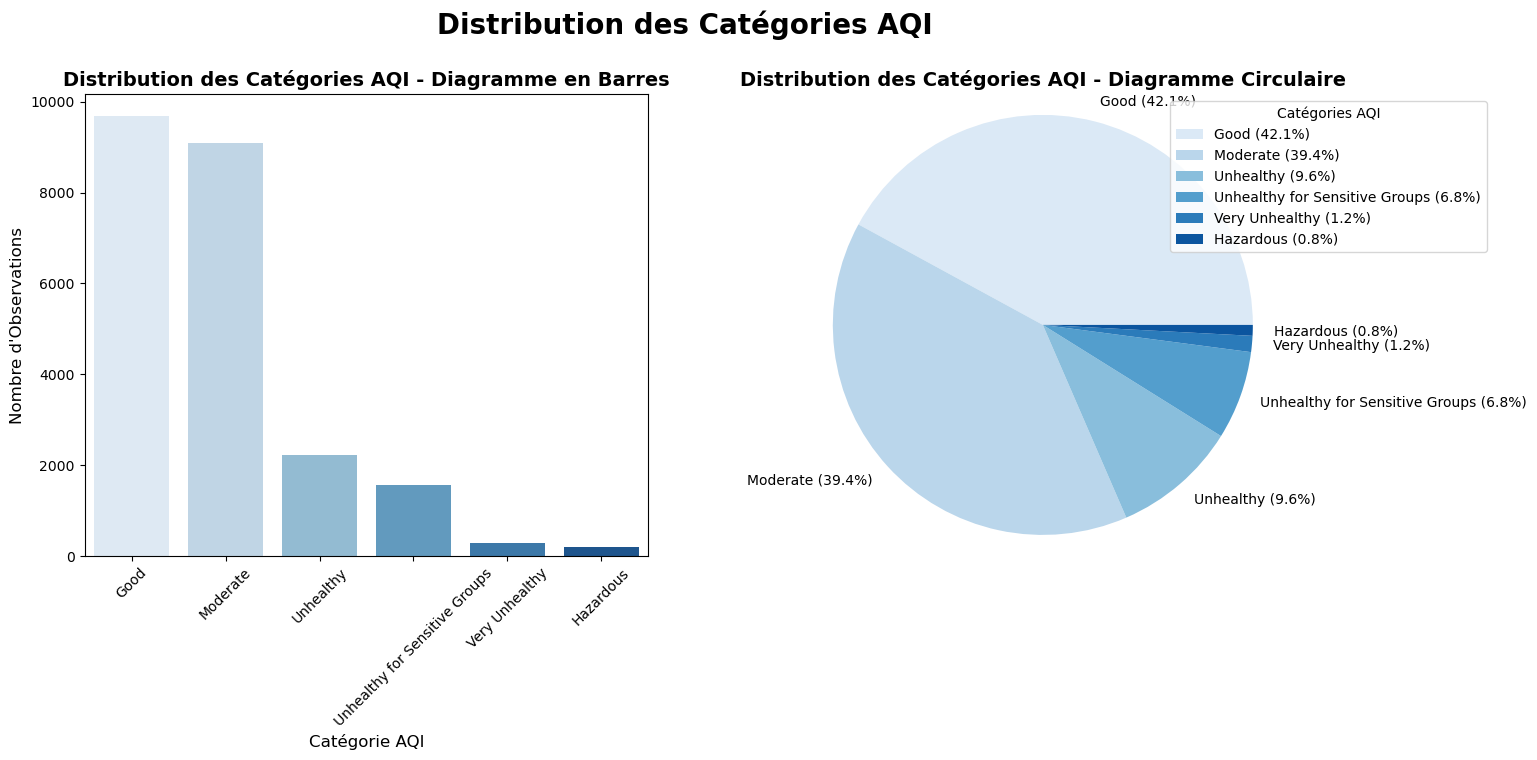

In [7]:
# 1. AQI Category - Diagramme en Barres / Pie Chart
data_counts = df['AQI Category'].value_counts().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Distribution des Catégories AQI', fontsize=20, fontweight='bold', y=1.02)

# Bar plot
sns.barplot(x=data_counts.index, y=data_counts.values, palette='Blues',hue=data_counts.index, ax=axes[0])
axes[0].set_title('Distribution des Catégories AQI - Diagramme en Barres', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Catégorie AQI', fontsize=12)
axes[0].set_ylabel('Nombre d\'Observations', fontsize=12)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

#pie chart
percentages = (data_counts.values / data_counts.sum()) * 100
labels_with_pct = [f'{label} ({pct:.1f}%)' for label, pct in zip(data_counts.index, percentages)]

axes[1].pie(data_counts.values, labels=labels_with_pct, colors=sns.color_palette('Blues'))
axes[1].set_title('Distribution des Catégories AQI - Diagramme Circulaire', fontsize=14, fontweight='bold')
axes[1].legend(title='Catégories AQI', loc='upper right', bbox_to_anchor=(1.3, 1))
axes[1].axis('equal')


plt.show()

### Interprétation - Distribution des Catégories AQI

**Observations :**
- **Good & Moderate** : Dominent (~42% et 39% respectivement)
- **Unhealthy** : Représente ~10% des observations
- **Hazardous** et **Very Unhealthy** : Très minoritaires (<2%)

**Décision :** Plus de 80% des régions ont une qualité d'air bonne à modérée. Problèmes graves concentrés dans <2% des cas.

C:\Users\Thin\AppData\Local\Temp\ipykernel_17852\1213374862.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=60)


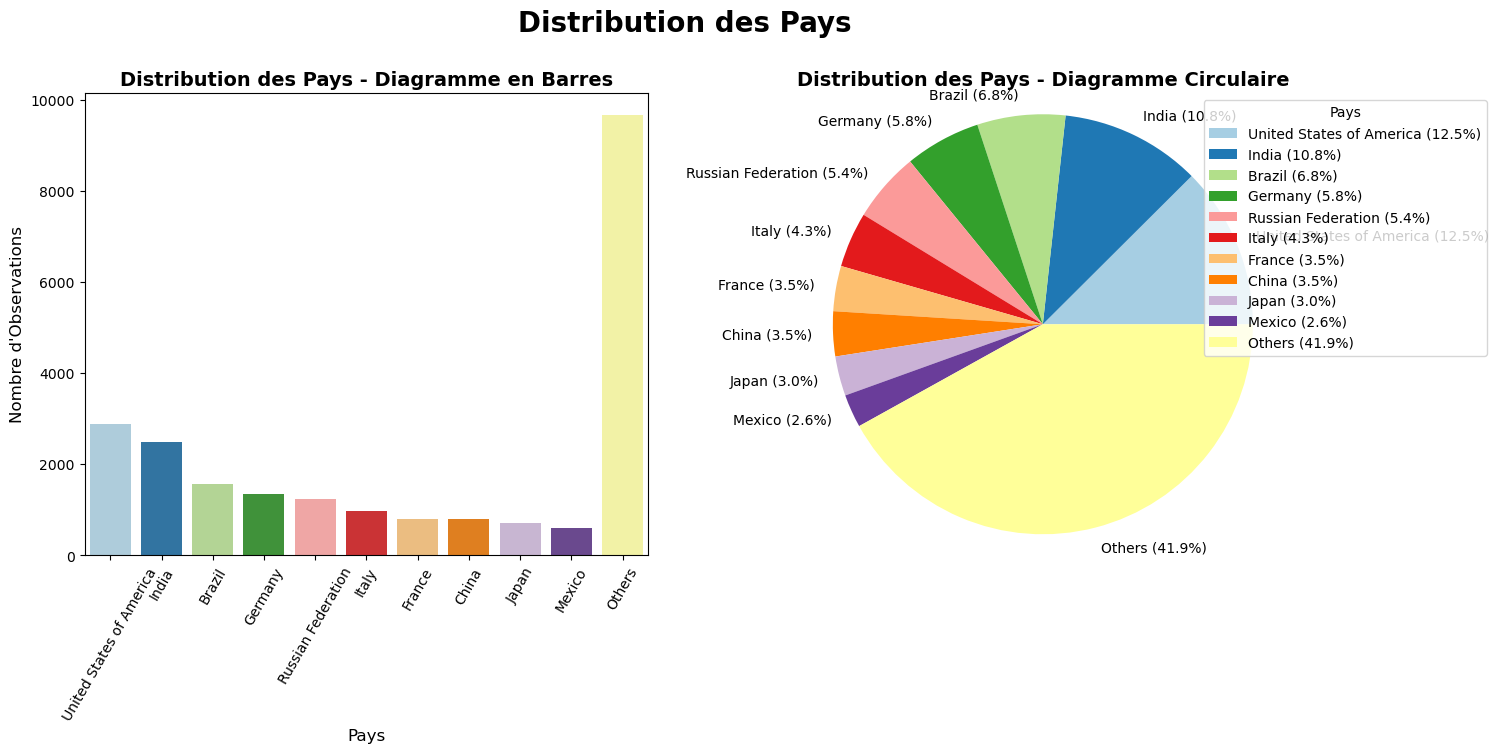

In [8]:
# 6. Country -  (Top 10 + Others)
data_counts = df['Country'].value_counts()

# Prendre les top 10 et grouper les autres
top_countries = data_counts.head(10)
others_count = data_counts.iloc[10:].sum() 
if others_count > 0:
    top_countries = pd.concat([top_countries, pd.Series({'Others': others_count})])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Distribution des Pays', fontsize=20, fontweight='bold', y=1.02)

# Bar plot
sns.barplot(x=top_countries.index, y=top_countries.values, palette='Paired',hue=top_countries.index, ax=axes[0])
axes[0].set_title('Distribution des Pays - Diagramme en Barres', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Pays', fontsize=12)
axes[0].set_ylabel('Nombre d\'Observations', fontsize=12)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=60)

# Pie chart
percentages = (top_countries.values / top_countries.sum()) * 100
labels_with_pct = [f'{label} ({pct:.1f}%)' for label, pct in zip(top_countries.index, percentages)]
axes[1].pie(top_countries.values, labels=labels_with_pct, colors=sns.color_palette('Paired'))
axes[1].set_title('Distribution des Pays - Diagramme Circulaire', fontsize=14, fontweight='bold')
axes[1].legend(title='Pays', loc='upper right', bbox_to_anchor=(1.3, 1))
axes[1].axis('equal')
plt.show()

### Interprétation - Distribution par Pays

**Observations :**
- **Top 10 pays** : Représentent ~58% des observations
- **Others** : Catégorie dominante (~42% des 150+ autres pays)
- **Leaders** : États-Unis, Inde, Brésil en tête

**Décision :** Données très dispersées géographiquement. Pas de concentration excessive - bonne couverture mondiale.

In [9]:
import plotly.graph_objects as go

data_counts = df['AQI Category'].value_counts().sort_values(ascending=False)
cumulative_pct = (data_counts.values.cumsum() / data_counts.sum()) * 100

fig = go.Figure()
fig.add_trace(go.Bar(x=data_counts.index, y=data_counts.values, name='Count'))
fig.add_trace(go.Scatter(x=data_counts.index, y=cumulative_pct, mode='lines+markers', name='% Cumulatif', yaxis='y2'))

fig.update_layout(
    title='Pareto - Catégories AQI',
    xaxis=dict(title='Catégorie AQI'),
    yaxis=dict(title='Nombre'),
    yaxis2=dict(title='% Cumulatif', overlaying='y', side='right')
)
fig.show()

### Interprétation - Diagramme de Pareto (AQI Category)

**Règle de Pareto 80/20 :**
- **Good seul** : ~42%
- **Good + Moderate** : ~81% (atteint exactement les 80%)
- Les 2 premières catégories expliquent 80% des données

**Décision :** Stratégie simple : cibler les régions "Moderate" pour les passer à "Good" résoudrait 80% des enjeux de qualité d'air.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation Bivariees
- Quantitatives-Quantitatives
</div>

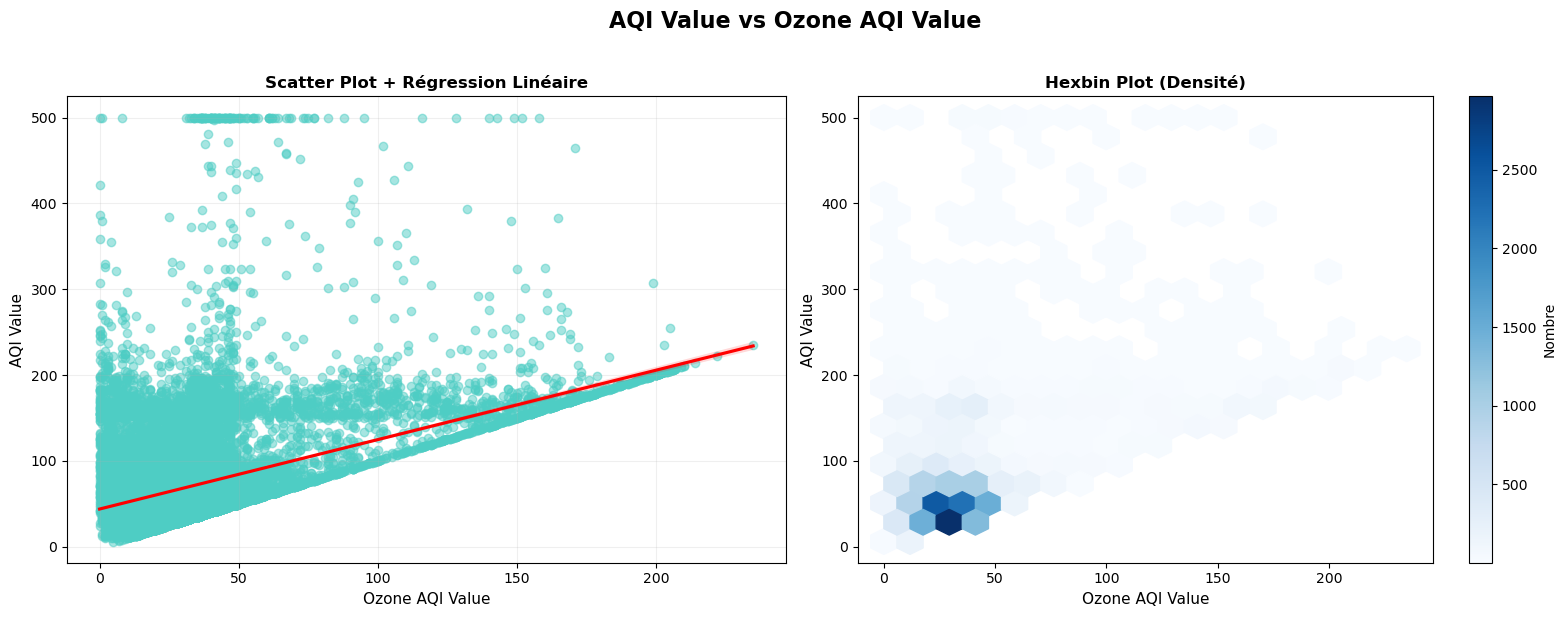

Corrélation de Pearson : 0.405


In [10]:
# Scatter plot avec régression - AQI Value vs Ozone AQI Value
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('AQI Value vs Ozone AQI Value', fontsize=16, fontweight='bold', y=1.02)

# Scatter plot avec regression
sns.regplot(data=df, x='Ozone AQI Value', y='AQI Value', ax=axes[0], scatter_kws={'alpha':0.5, 'color':'#4ECDC4'}, line_kws={'color':'red'})
axes[0].set_title('Scatter Plot + Régression Linéaire', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ozone AQI Value', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].grid(True, alpha=0.2)

# Hexbin plot (densité)
hexbin = axes[1].hexbin(df['Ozone AQI Value'], df['AQI Value'], gridsize=20, cmap='Blues', mincnt=1)
axes[1].set_title('Hexbin Plot (Densité)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Ozone AQI Value', fontsize=11)
axes[1].set_ylabel('AQI Value', fontsize=11)
plt.colorbar(hexbin, ax=axes[1], label='Nombre')

plt.tight_layout()
plt.show()

# Calculer et afficher la corrélation
corr = df['AQI Value'].corr(df['Ozone AQI Value'])
print(f"Corrélation de Pearson : {corr:.3f}")

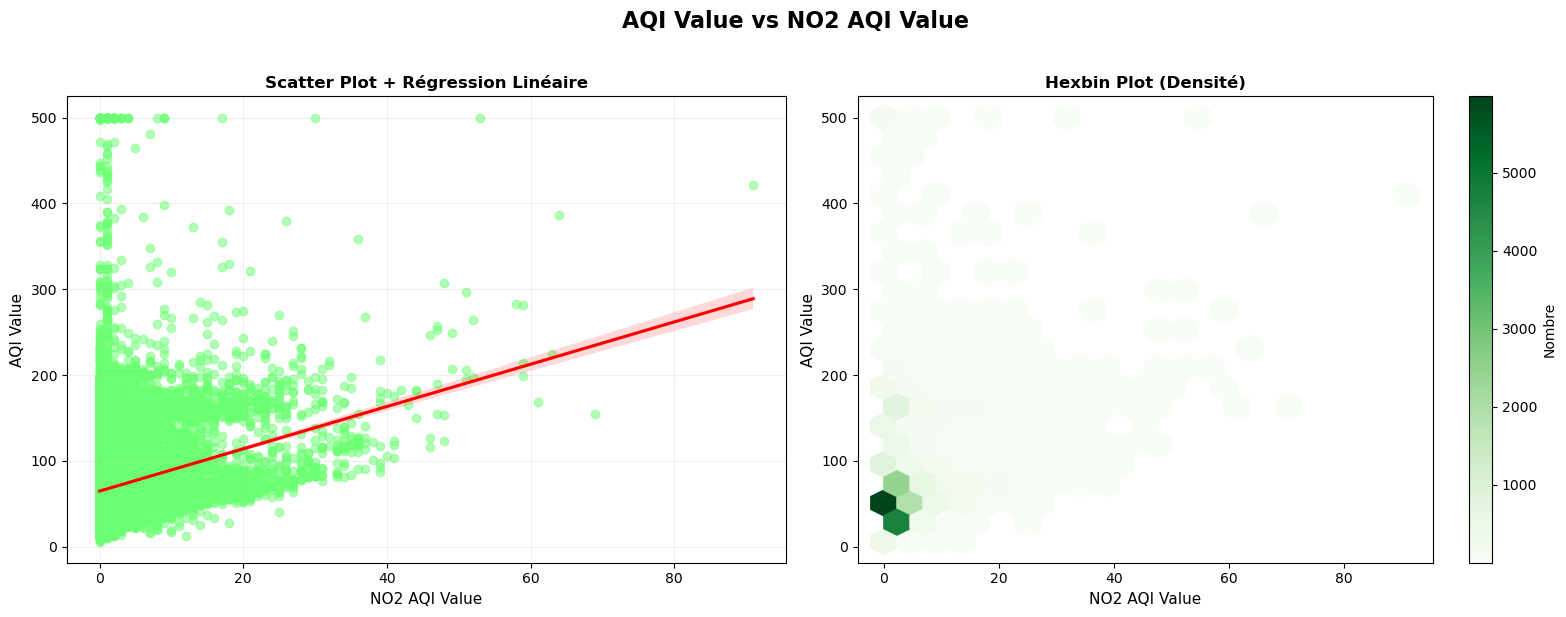

In [11]:
# AQI Value vs NO2 AQI Value
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('AQI Value vs NO2 AQI Value', fontsize=16, fontweight='bold', y=1.02)

#scatter plot avec regression
sns.regplot(data=df, x='NO2 AQI Value', y='AQI Value', ax=axes[0], scatter_kws={'alpha':0.5, 'color':"#6BFF72"}, line_kws={'color':'red'})
axes[0].set_title('Scatter Plot + Régression Linéaire', fontsize=12, fontweight='bold')
axes[0].set_xlabel('NO2 AQI Value', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].grid(True, alpha=0.2)  

# Hexbin plot (densité)
hexbin = axes[1].hexbin(df['NO2 AQI Value'], df['AQI Value'], gridsize=20, cmap='Greens', mincnt=1)
axes[1].set_title('Hexbin Plot (Densité)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('NO2 AQI Value', fontsize=11)
axes[1].set_ylabel('AQI Value', fontsize=11)
plt.colorbar(hexbin, ax=axes[1], label='Nombre')
plt.tight_layout()
plt.show()

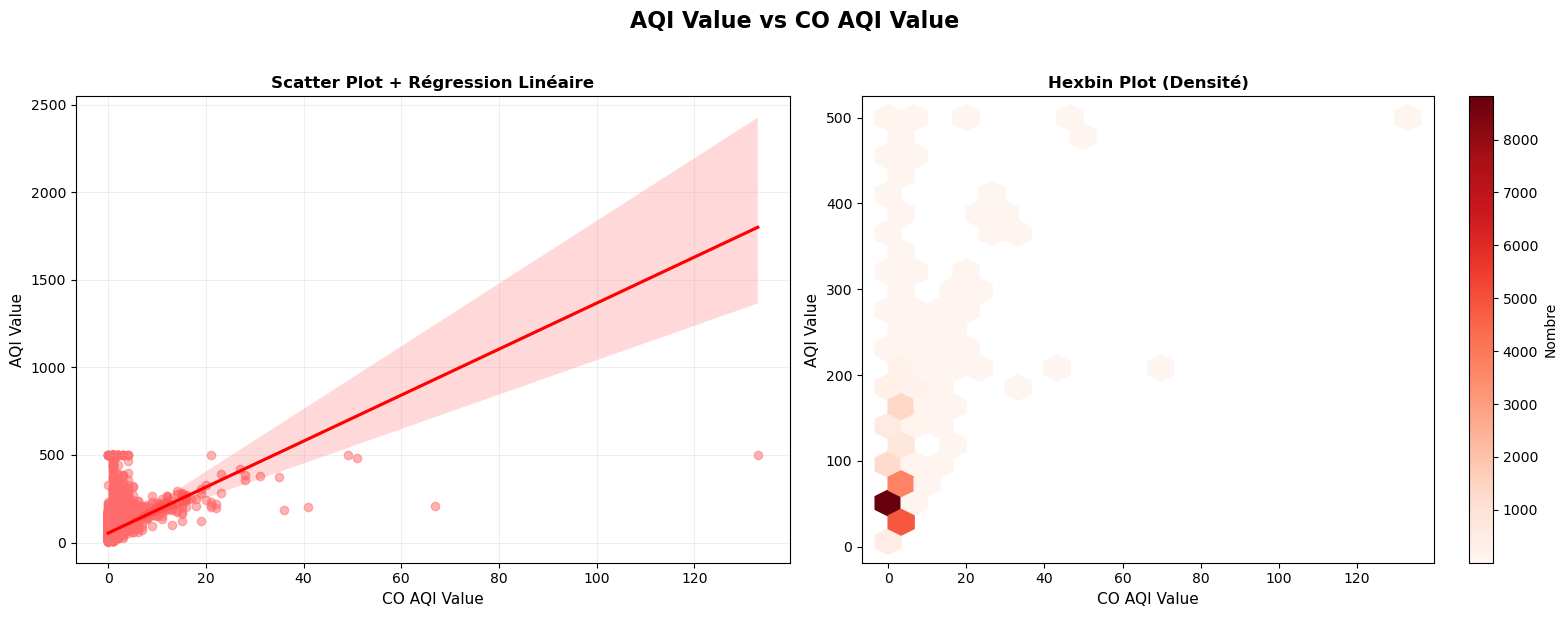

In [12]:
# AQI vs CO AQI Value
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('AQI Value vs CO AQI Value', fontsize=16, fontweight='bold', y=1.02)
# Scatter plot avec regression
sns.regplot(data=df, x='CO AQI Value', y='AQI Value', ax=axes[0], scatter_kws={'alpha':0.5, 'color':'#FF6B6B'}, line_kws={'color':'red'})
axes[0].set_title('Scatter Plot + Régression Linéaire', fontsize=12, fontweight='bold')
axes[0].set_xlabel('CO AQI Value', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].grid(True, alpha=0.2)
# Hexbin plot (densité)
hexbin = axes[1].hexbin(df['CO AQI Value'], df['AQI Value'], gridsize=20, cmap='Reds', mincnt=1)
axes[1].set_title('Hexbin Plot (Densité)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('CO AQI Value', fontsize=11)
axes[1].set_ylabel('AQI Value', fontsize=11)
plt.colorbar(hexbin, ax=axes[1], label='Nombre')
plt.tight_layout()
plt.show()

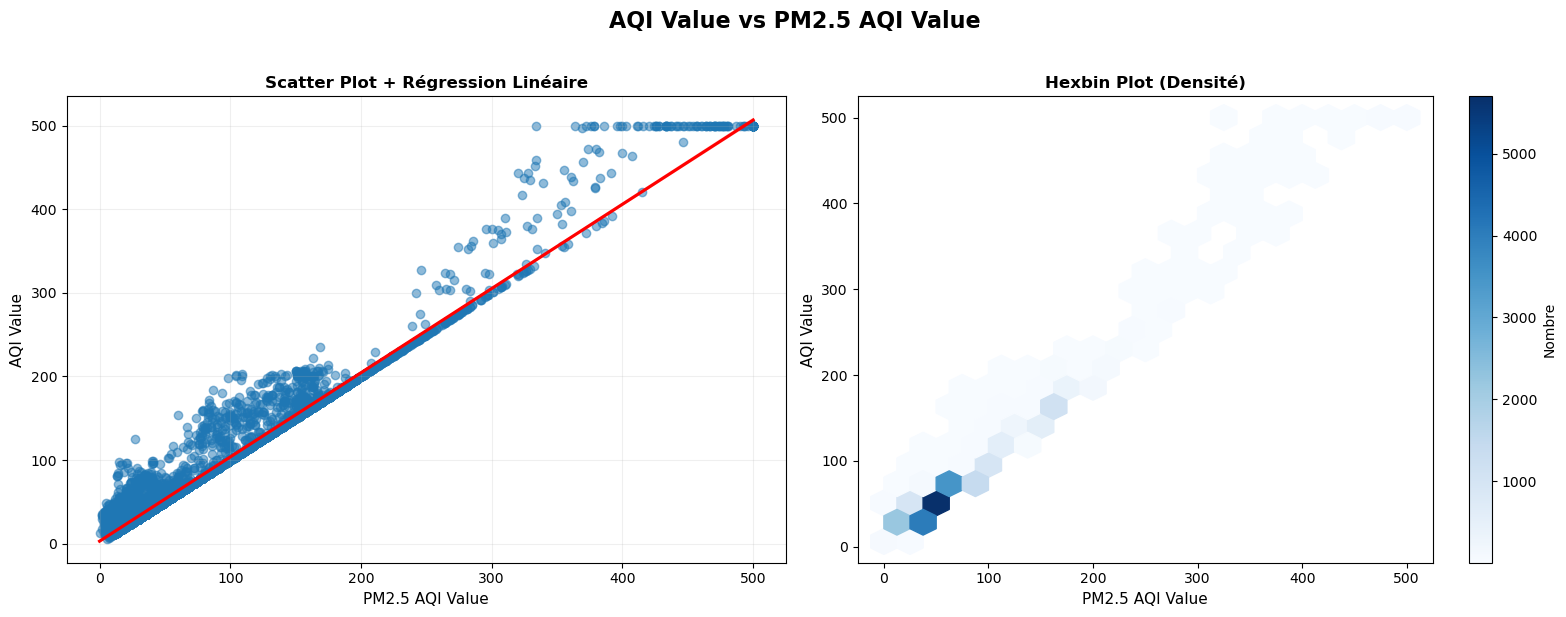

Corrélation de Pearson : 0.985


In [13]:
# Scatter plot avec régression linéaire - AQI Value vs PM2.5
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('AQI Value vs PM2.5 AQI Value', fontsize=16, fontweight='bold', y=1.02)

# Scatter plot avec regression
sns.regplot(data=df, x='PM2.5 AQI Value', y='AQI Value', ax=axes[0], scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
axes[0].set_title('Scatter Plot + Régression Linéaire', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PM2.5 AQI Value', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].grid(True, alpha=0.2)

# Hexbin plot (densité)
hexbin = axes[1].hexbin(df['PM2.5 AQI Value'], df['AQI Value'], gridsize=20, cmap='Blues', mincnt=1)
axes[1].set_title('Hexbin Plot (Densité)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('PM2.5 AQI Value', fontsize=11)
axes[1].set_ylabel('AQI Value', fontsize=11)
plt.colorbar(hexbin, ax=axes[1], label='Nombre')

plt.tight_layout()
plt.show()

# Calculer et afficher la corrélation
corr = df['AQI Value'].corr(df['PM2.5 AQI Value'])
print(f"Corrélation de Pearson : {corr:.3f}")

### Interprétation - Visualisations Quantitatives ↔ Quantitatives

**Analyse comparative des polluants sur la valeur AQI globale :**

**Principal finding - PM2.5 : Polluant dominant**
- **Relation linéaire** : PM2.5 montre une relation **presque parfaitement linéaire** avec la valeur AQI globale
- **Impact maximal** : C'est le polluant qui affecte le plus la qualité de l'air globale
- **Pattern observable** : À mesure que PM2.5 augmente, la valeur AQI augmente proportionnellement de façon cohérente
- **Conclusion** : PM2.5 est le major driver de la qualité d'air mondiale

**Autres polluants (Ozone, CO, NO2) :**
- Montrent des relations plus faibles ou dispersées avec l'AQI global
- Impact moins direct sur la valeur d'AQI comparé à PM2.5

**Décision stratégique** : Réduire les niveaux de PM2.5 est la priorité absolue pour améliorer la qualité d'air globale.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation Bivariees
- Qualitatives-Quantitatives
</div>

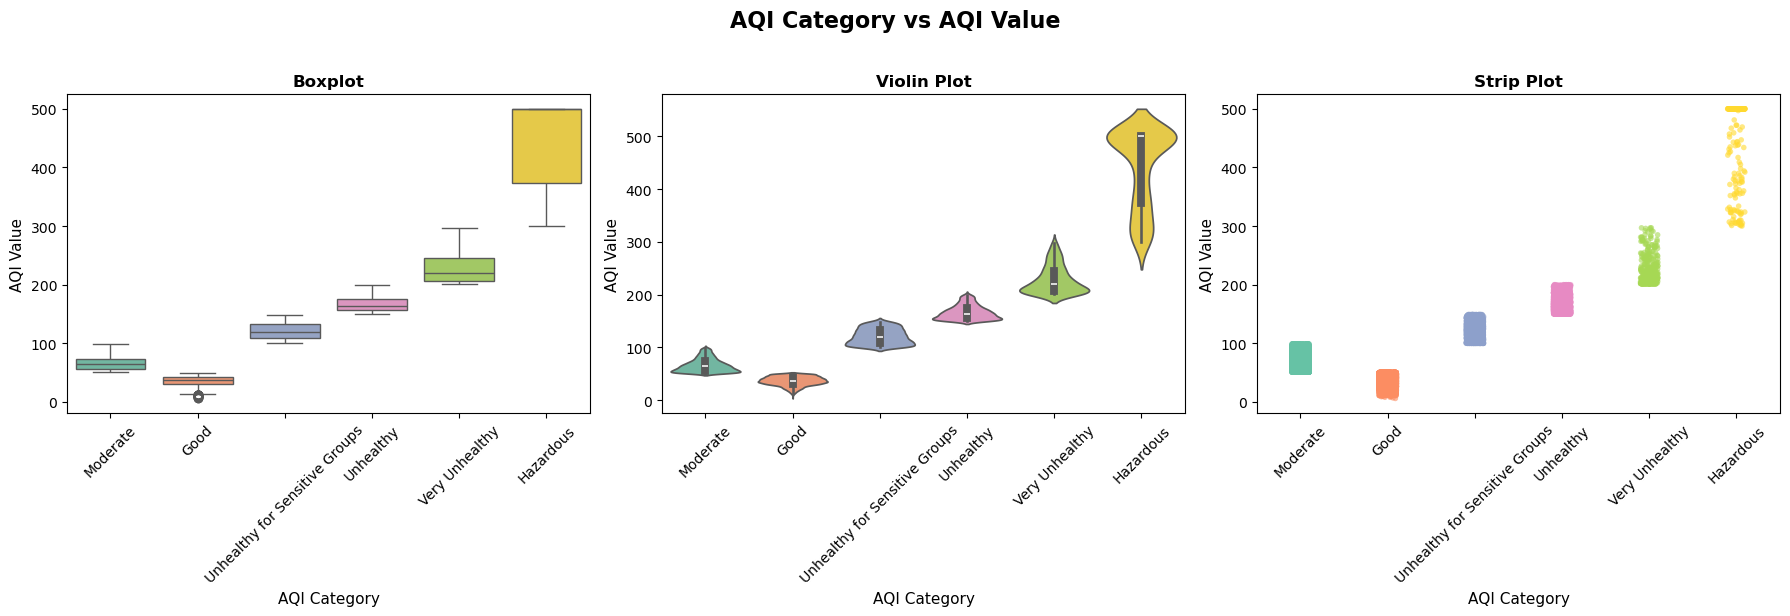

In [14]:
# AQI Category vs AQI Value - Boxplot, Violin plot, Swarm plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('AQI Category vs AQI Value', fontsize=16, fontweight='bold', y=1.02)

# Boxplot
sns.boxplot(data=df, x='AQI Category', y='AQI Value', hue='AQI Category', ax=axes[0], palette='Set2')
axes[0].set_title('Boxplot', fontsize=12, fontweight='bold')
axes[0].set_xlabel('AQI Category', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# Violin plot
sns.violinplot(data=df, x='AQI Category', y='AQI Value', hue='AQI Category', ax=axes[1], palette='Set2')
axes[1].set_title('Violin Plot', fontsize=12, fontweight='bold')
axes[1].set_xlabel('AQI Category', fontsize=11)
axes[1].set_ylabel('AQI Value', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

# Strip plot (avec alpha pour transparence)
sns.stripplot(data=df, x='AQI Category', y='AQI Value', ax=axes[2], hue='AQI Category', palette='Set2', size=4, alpha=0.6)
axes[2].set_title('Strip Plot', fontsize=12, fontweight='bold')
axes[2].set_xlabel('AQI Category', fontsize=11)
axes[2].set_ylabel('AQI Value', fontsize=11)
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Interprétation - AQI Category vs AQI Value

**Observations :**
- **Range des catégories** : La catégorie "Hazardous" présente le plus large range, s'étendant de 250 à 500
- **Autres catégories** : Les autres catégories (Good, Moderate, Unhealthy) ont des ranges plus compacts
- **Pattern observable** : À mesure que la catégorie s'aggrave, les valeurs AQI augmentent proportionnellement

**Décision** : La distinction entre catégories est bien marquée, avec "Hazardous" représentant les niveaux les plus critiques.

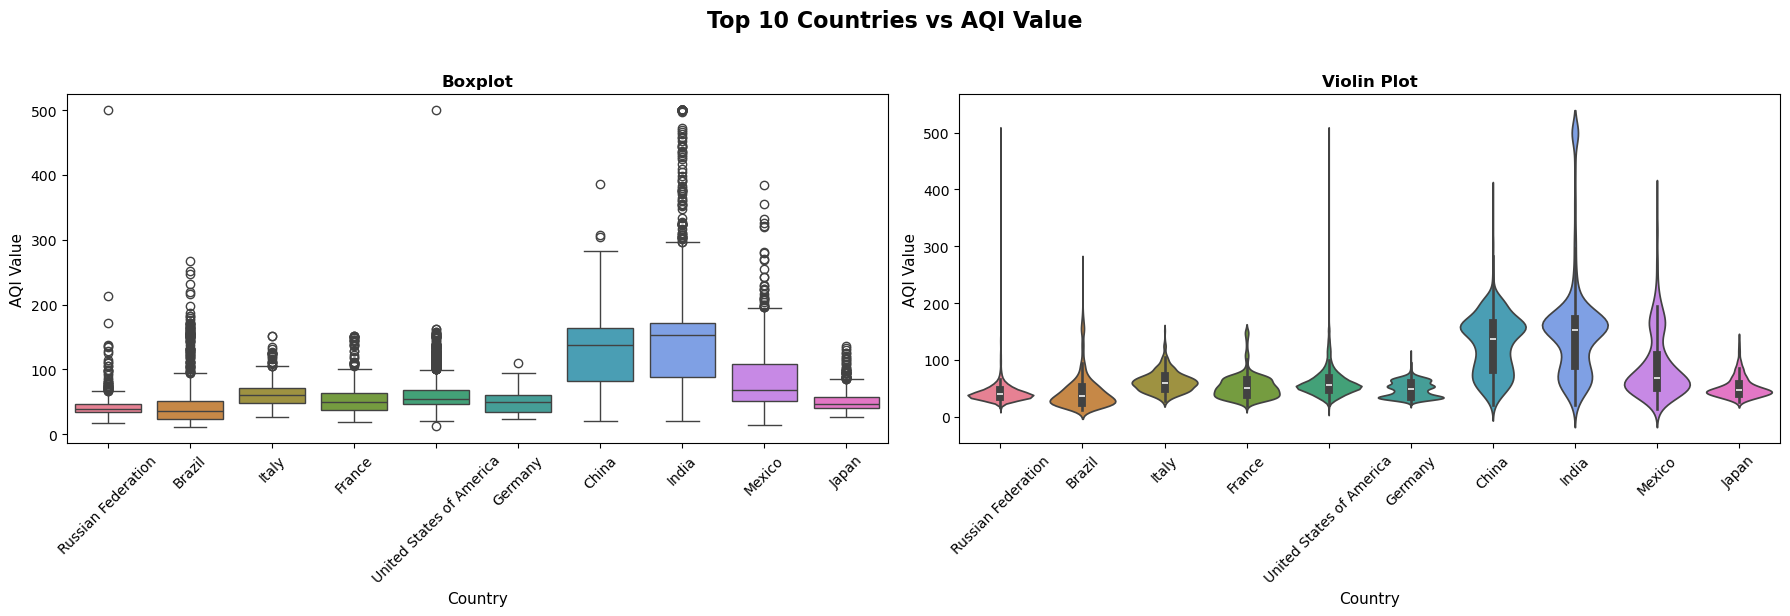

In [15]:
# Top 10 Countries vs AQI Value - Boxplot et Violin plot
top_10_countries = df['Country'].value_counts().head(10).index
df_top10 = df[df['Country'].isin(top_10_countries)]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Top 10 Countries vs AQI Value', fontsize=16, fontweight='bold', y=1.02)

# Boxplot
sns.boxplot(data=df_top10, x='Country', y='AQI Value', hue='Country', ax=axes[0], palette='husl')
axes[0].set_title('Boxplot', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Country', fontsize=11)
axes[0].set_ylabel('AQI Value', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# Violin plot
sns.violinplot(data=df_top10, x='Country', y='AQI Value', hue='Country', ax=axes[1], palette='husl')
axes[1].set_title('Violin Plot', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Country', fontsize=11)
axes[1].set_ylabel('AQI Value', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Interprétation - Top 10 Countries vs AQI Value

**Observations clés :**
- **Outliers en Inde** : L'Inde présente une concentration exceptionnelle d'outliers, indiquant de nombreuses villes avec une qualité d'air très dégradée
- **Problème urbain** : Ces outliers reflètent la variabilité extrême de la qualité d'air entre différentes villes indiennes
- **Autres pays** : La plupart des autres pays du Top 10 montrent une distribution plus homogène, avec l'Inde se démarquant clairement

**Décision** : L'Inde nécessite une attention particulière avec des interventions ciblées par ville pour réduire cette extrême variabilité de pollution urbaine.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation Bivariees
- Qualitatives-Qualitatives
</div>

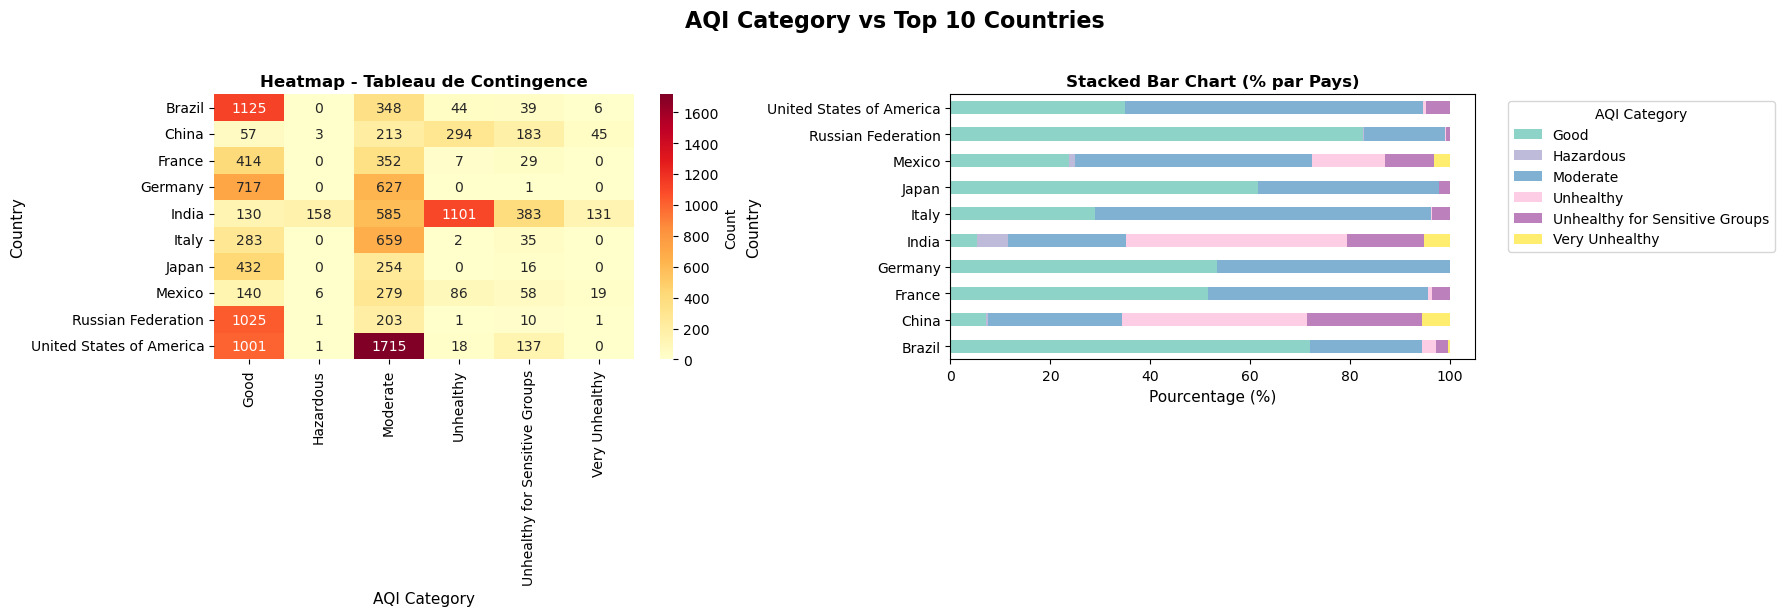

In [16]:
# AQI Category vs Top 10 Countries - Heatmap du tableau de contingence
top_10_countries = df['Country'].value_counts().head(10).index
df_top10 = df[df['Country'].isin(top_10_countries)]

# Créer le tableau de contingence
contingency_table = pd.crosstab(df_top10['Country'], df_top10['AQI Category'])

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('AQI Category vs Top 10 Countries', fontsize=16, fontweight='bold', y=1.02)

# Heatmap
sns.heatmap(contingency_table, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Heatmap - Tableau de Contingence', fontsize=12, fontweight='bold')
axes[0].set_xlabel('AQI Category', fontsize=11)
axes[0].set_ylabel('Country', fontsize=11)

# Stacked bar chart (normalisé en pourcentage)
contingency_pct = contingency_table.div(contingency_table.sum(axis=1), axis=0) * 100
contingency_pct.plot(kind='barh', stacked=True, ax=axes[1], colormap='Set3')
axes[1].set_title('Stacked Bar Chart (% par Pays)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Pourcentage (%)', fontsize=11)
axes[1].set_ylabel('Country', fontsize=11)
axes[1].legend(title='AQI Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

### Interprétation - AQI Category vs Top 10 Countries (Heatmap & Stacked Bar)

**Observations clés :**
- **États-Unis** : Profil positif avec une majorité d'observations dans les catégories "Good" ou "Moderate"
- **Inde** : Présente plus de 1 000 observations avec la catégorie "Unhealthy" - problème majeur de pollution urbaine
- **Brésil** : Plus de 1 000 observations dans la catégorie "Good"

**Important - Clarification sur les données :**
- Les nombres représentent des **observations/counts**, non des villes uniques
- Probable que certaines villes se répètent plusieurs fois dans le dataset (mesures multiples, périodes différentes, capteurs multiples)
- Par exemple : Brésil n'a pas 1 125 villes distinctes, mais 1 125 observations enregistrées

**Décision** : L'Inde requiert des interventions urgentes pour réduire la proportion d'observations en catégorie "Unhealthy". Les États-Unis et le Brésil montrent une meilleure situation globale, mais avec des outliers à surveiller.

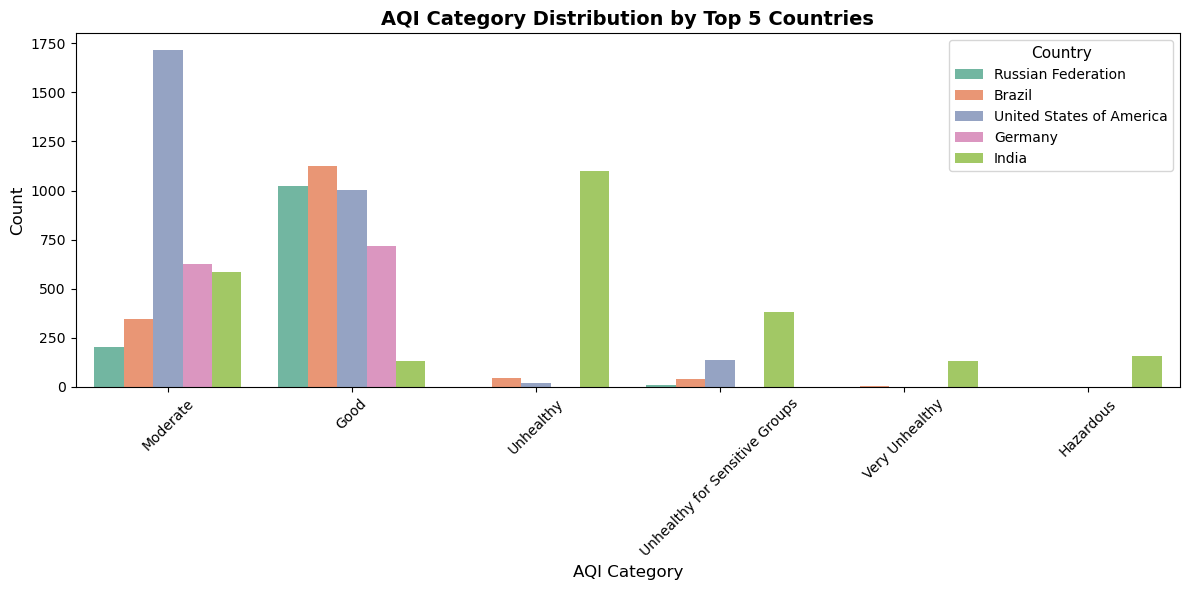

In [17]:
# Countplot croisé - AQI Category vs Top 5 Countries (diagramme en barres groupées)
top_5_countries = df['Country'].value_counts().head(5).index
df_top5 = df[df['Country'].isin(top_5_countries)]

fig, ax = plt.subplots(figsize=(12, 6))

# Countplot avec hue (groupé par pays)
sns.countplot(data=df_top5, x='AQI Category', hue='Country', ax=ax, palette='Set2')
ax.set_title('AQI Category Distribution by Top 5 Countries', fontsize=14, fontweight='bold')
ax.set_xlabel('AQI Category', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Country', title_fontsize=11, fontsize=10)
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Interprétation - AQI Category Distribution by Top 5 Countries

**Observations clés :**
- **Catégorie Moderate** : États-Unis domine avec plus de 1 500 observations
- **Catégorie Good** : Fédération de Russie, Brésil et Allemagne montrent un grand nombre d'observations
- **Catégories critiques (Unhealthy+)** : L'Inde concentre la majorité des observations dans les catégories "Unhealthy", "Unhealthy for Sensitive Groups", "Very Unhealthy" et "Hazardous"

**Décision** : Confirmation que l'Inde est le pays prioritaire pour les interventions de qualité d'air, tandis que les États-Unis, Russie, Brésil et Allemagne maintiennent de meilleures conditions globales.

In [18]:
# Les meilleures pays du monde (Les "Heroes")
import plotly.express as px
# We use the average per country to find the cleanest nations overall
best_countries = df.groupby('Country')['AQI Value'].mean().nsmallest(5).reset_index()

fig_best = px.bar(
    best_countries, 
    x='AQI Value', 
    y='Country', 
    color='AQI Value',
    orientation='h',
    title='World Heroes: 5 Countries with the Cleanest Air',
    color_continuous_scale=px.colors.sequential.Greens_r,
    template="plotly_dark"
)
fig_best.update_layout(yaxis={'categoryorder':'total descending'})
fig_best.show()

### Interprétation - World Heroes: 5 Countries with the Cleanest Air

**Observations :**
- **Palau** : Meilleur AQI global avec une valeur moyenne très basse (~16)
- **Solomon Islands, Maldives, Iceland, Bolivia** : AQI moyen entre 22-25, indiquant une excellente qualité d'air
- **Pattern** : Tous les 5 pays "heroes" ont des AQI values bien en dessous de 50, ce qui correspond à une catégorie "Good"

**Décision** : Ces pays servent de modèles de référence pour une qualité d'air exceptionnelle et peuvent inspirer les stratégies d'amélioration pour les pays à plus haute pollution.

In [19]:
# FIVE WORST COUNTRIES (Highest Average AQI)
# We calculate the mean per country to avoid single-city sensor errors
worst_countries = df.groupby('Country')['AQI Value'].mean().nlargest(5).reset_index()

fig_worst = px.bar(
    worst_countries, 
    x='AQI Value', 
    y='Country', 
    color='AQI Value',
    orientation='h',
    title='World Villains: 5 Most Polluted Countries (Average AQI)',
    color_continuous_scale=px.colors.sequential.Reds, # Red for danger
    template="plotly_dark"
)
fig_worst.update_layout(yaxis={'categoryorder':'total ascending'})
fig_worst.show()

### Interprétation - World Villains: 5 Most Polluted Countries (Average AQI)

**Observations clés :**
- **République de Corée** : Domine le classement avec l'AQI moyen le plus élevé (~430+)
- **Bahrain, Mauritania, Pakistan, United Arab Emirates** : AQI moyens entre 170-200, considérés comme très pollués
- **Absence notable : L'Inde** : N'apparaît pas dans ce classement car bien qu'elle ait de nombreuses observations très polluées, la moyenne est tirée vers le bas par les villes avec une bonne qualité d'air

**Important - Distinction average vs distribution :**
- Ce graphique montre les **moyennes par pays**, différent de la distribution complète
- L'Inde a des extrêmes (certaines villes très propres, d'autres très polluées), ce qui donne une moyenne modérée
- La République de Corée a une pollution plus **homogène** et systématiquement élevée

**Décision** : La République de Corée nécessite une intervention urgente et massive. L'absence de l'Inde souligne l'importance d'analyser à la fois les moyennes ET la distribution pour une vision complète.

In [20]:
# 4. Pollutant breakdown for those worst countries
# Let's see what makes up the AQI in the 5 most polluted countries
top_5_polluted_countries = df.groupby('Country')['AQI Value'].mean().nlargest(5).index
pollutant_df = df[df['Country'].isin(top_5_polluted_countries)]
pollutant_avg = pollutant_df.groupby('Country')[['CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']].mean().reset_index()

# Melt the data for Plotly grouped bar chart
melted_pollutants = pollutant_avg.melt(id_vars='Country', var_name='Pollutant', value_name='AQI')

fig_pollutants = px.bar(
    melted_pollutants, 
    x='Country', 
    y='AQI', 
    color='Pollutant', 
    barmode='group',
    title='Comparison of Specific Pollutants in Top 5 Most Polluted Countries',
    template="plotly_dark"
)
fig_pollutants.show()

### Interprétation - Comparison of Specific Pollutants in Top 5 Most Polluted Countries

**Observation clé - PM2.5 est le polluant dominant :**
- **PM2.5** : Représente la part majeure de la pollution dans tous les 5 pays polluants
  - République de Corée : ~400+ AQI (le polluant dominant, largement supérieur aux autres)
  - Bahrain, Mauritania, Pakistan, UAE : PM2.5 est systématiquement le plus élevé
- **Autres polluants** : 
  - Ozone : Présent mais significativement moins important que PM2.5
  - CO et NO2 : Contributions mineures à la pollution globale
  
**Pattern identifié :**
- La domination du PM2.5 dans les 5 pays les plus pollués confirme les résultats de l'analyse bivariée quantitative
- PM2.5 est le **problème critiquement majeur** affectant la qualité de l'air mondiale

**Décision stratégique :** Les interventions de réduction de PM2.5 doivent être la priorité absolue dans ces 5 pays, car elles auraient un impact maximal sur l'amélioration de la qualité de l'air globale.

In [21]:
# Les meilleures villes du Maroc (5 villes les plus propres)
# Filter les données pour le Maroc et trouver les 5 villes avec les AQI les plus bas

morocco_df = df[df['Country'] == 'Morocco']
best_5_morocco = morocco_df.nsmallest(5, 'AQI Value')

fig_best_morocco = px.bar(
    best_5_morocco, 
    x='AQI Value', 
    y='City', 
    color='AQI Value',
    orientation='h',
    title='Top 5 Cleanest Cities in Morocco',
    color_continuous_scale=px.colors.sequential.Greens_r, 
    text='AQI Value'
)
# Order the y-axis so the lowest AQI is at the top
fig_best_morocco.update_layout(yaxis={'categoryorder':'total descending'})
fig_best_morocco.update_traces(textposition='outside')


fig_best_morocco.show()

### Interprétation - Top 5 Cleanest Cities in Morocco

**Observations :**
- **Azimur** : La plus propre avec AQI = 27 (catégorie "Good")
- **Tarudant** : AQI = 29 (catégorie "Good")
- **Asfi** : AQI = 33 (catégorie "Good")
- **Fez, Casablanca** : AQI = 37 (catégorie "Good", légèrement moins propres)

**Pattern identifié :**
- Toutes les 5 villes ont des AQI values dans la plage 27-37, correspondant à une excellente qualité d'air
- La différence entre la meilleure (27) et la moins bonne (37) est minime (10 points)
- Le Maroc montre une bonne performance globale avec des villes relativement propres

**Décision** : Le Maroc peut servir de modèle régional pour maintenir une bonne qualité d'air, bien que même Casablanca (plus grande ville) reste dans la catégorie "Good".

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation multivariees
Scatter Plots Multivariés
</div>

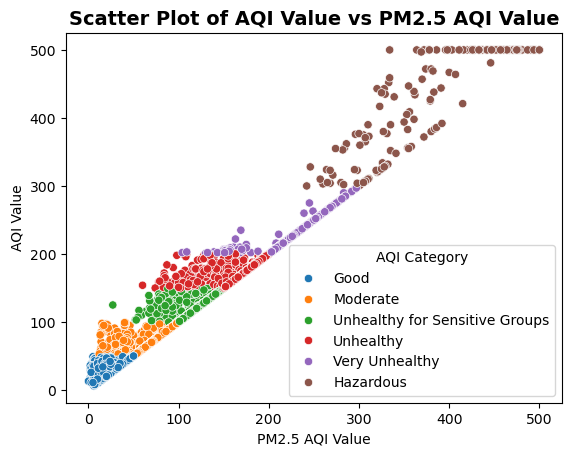

In [22]:
# scatter plot multiple variables - AQI Value, PM2.5

fig = sns.scatterplot(
    df, 
    x='PM2.5 AQI Value', 
    y='AQI Value', 
    hue='AQI Category',
    hue_order=['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
   
)

plt.title('Scatter Plot of AQI Value vs PM2.5 AQI Value', fontsize=14, fontweight='bold')
plt.show()

### Interprétation - Scatter Plot: AQI Value vs PM2.5 AQI Value

**Observations clés :**
- **Relation linéaire très forte** : La correlation entre PM2.5 et AQI Value est quasi-parfaite, montrant une tendance linéaire prononcée
- **Clustering par catégorie** : Les points sont clairement ségrégés par couleur (catégories AQI), confirmant que PM2.5 est le principal déterminant de la classification AQI


**Conclusion majeure** :
PM2.5 est le polluant dominant qui explique la quasi-totalité de la variabilité de l'AQI global. Réduire les niveaux de PM2.5 est donc la stratégie prioritaire pour améliorer la qualité de l'air mondiale.

##### On va ajouter un nouveau colonne pour les continents pour faire des graph multiples

In [23]:


# Step 1: Add continent column
import pycountry_convert as pc

def get_continent(country_name):
    try:
        country_alpha2 = pc.country_name_to_country_alpha2(country_name)
        country_continent = pc.country_alpha2_to_continent_code(country_alpha2)
        continent_name = pc.convert_continent_code_to_continent_name(country_continent)
        return continent_name
    except:
        return 'Unknown'

df['Continent'] = df['Country'].apply(get_continent)

# Step 2: Check for any issues
print("Unique continents:", df['Continent'].unique())
print("\nUnknown countries:", df[df['Continent'] == 'Unknown']['Country'].unique())

Unique continents: ['Europe' 'South America' 'North America' 'Africa' 'Asia' 'Oceania'
 'Unknown']

Unknown countries: ['Iran (Islamic Republic of)' 'Bolivia (Plurinational State of)'
 'Venezuela (Bolivarian Republic of)' 'Republic of Korea'
 'State of Palestine']


La bibliothèque PyCountry n'a pas reconnu certains pays de notre Dataset, nous allons donc les cartographier manuellement.

In [24]:
# manual mapping for any unknowns
manual_mapping = {
'Iran (Islamic Republic of)': 'Asia',
'Bolivia (Plurinational State of)': 'Americas',
'Venezuela (Bolivarian Republic of)': 'Americas',
'Republic of Korea': 'Asia',
'State of Palestine': 'Asia',
'Russian Federation': 'Asia', 
'United States of America': 'Americas'}
# fill the 'unknown' values using the manual mapping
df['Continent'] = df.apply(
    
    lambda row: manual_mapping.get(row['Country'],
    row['Continent']) if row['Continent'] == 'Unknown' else row['Continent'],
    axis=1)


# grouping the 2 american continents into 'Americas'
df['Continent'] = df['Continent'].replace({'North America': 'Americas', 'South America': 'Americas'})

# Final check
print("Unique continents after manual mapping:", df['Continent'].unique())
print("\nUnknown countries:", df[df['Continent'] == 'Unknown']['Country'].unique())



Unique continents after manual mapping: ['Europe' 'Americas' 'Africa' 'Asia' 'Oceania']

Unknown countries: []


<Figure size 1600x800 with 0 Axes>

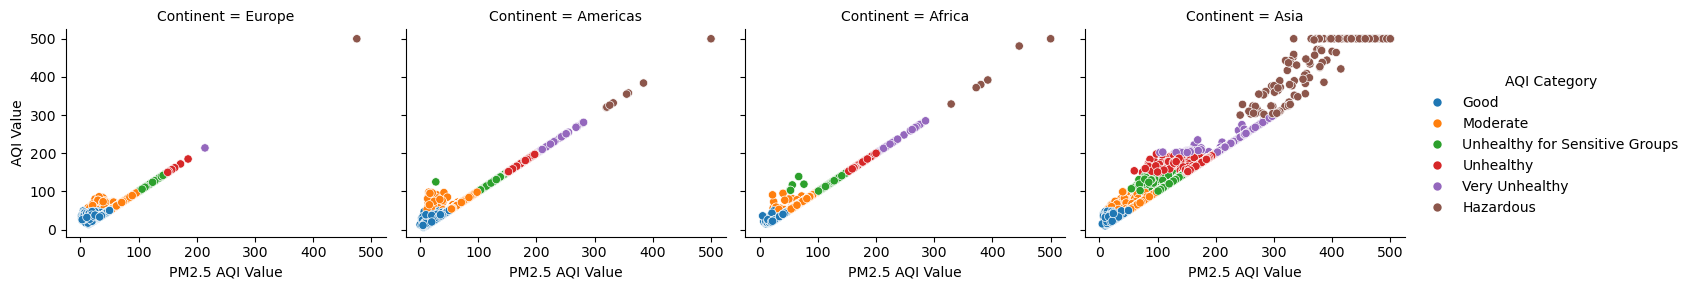

In [25]:
# scaterplot pour AQI Value vs PM2.5 AQI Value, coloré par continent
plt.figure(figsize=(16, 8))
sns.relplot(
    
    df[df['Continent'].isin(['Europe', 'Asia', 'Africa', 'Americas'])],
    x='PM2.5 AQI Value', 
    y='AQI Value', 
    hue='AQI Category',
    col='Continent',
    height=3,
    aspect=1.2,
    hue_order=['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
   
   
    
)
plt.show()


### Interprétation - AQI Value vs PM2.5 AQI Value par Continent

**Constat Principal :**
La relation linéaire entre PM2.5 et la valeur AQI globale **se confirme de manière cohérente across all continents**. Cette observation universelle renforce la conclusion que PM2.5 est le polluant dominant affectant la qualité de l'air mondiale.

**Observations clés par continent :**
- **Tous les continents** : Affichent la même tendance linéaire positive entre PM2.5 et AQI Value
- **Pattern global** : À mesure que PM2.5 augmente, la valeur AQI augmente proportionnellement, indépendamment de la région géographique
- **Cohérence des catégories** : Les couleurs (catégories AQI) s'alignent le long de cette droite linéaire, confirmant que PM2.5 est le principal déterminant de la classification AQI

**Conclusion :**
Cette visualisation multi-continentale valide notre hypothèse précédente : **PM2.5 est le polluant critique universel**. Les stratégies de réduction de PM2.5 doivent être une priorité mondiale, peu importe le continent, car elles auront un impact direct et proportionnel sur l'amélioration de la qualité de l'air globale.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation multivariees
BoxPlots Multivariés
</div>

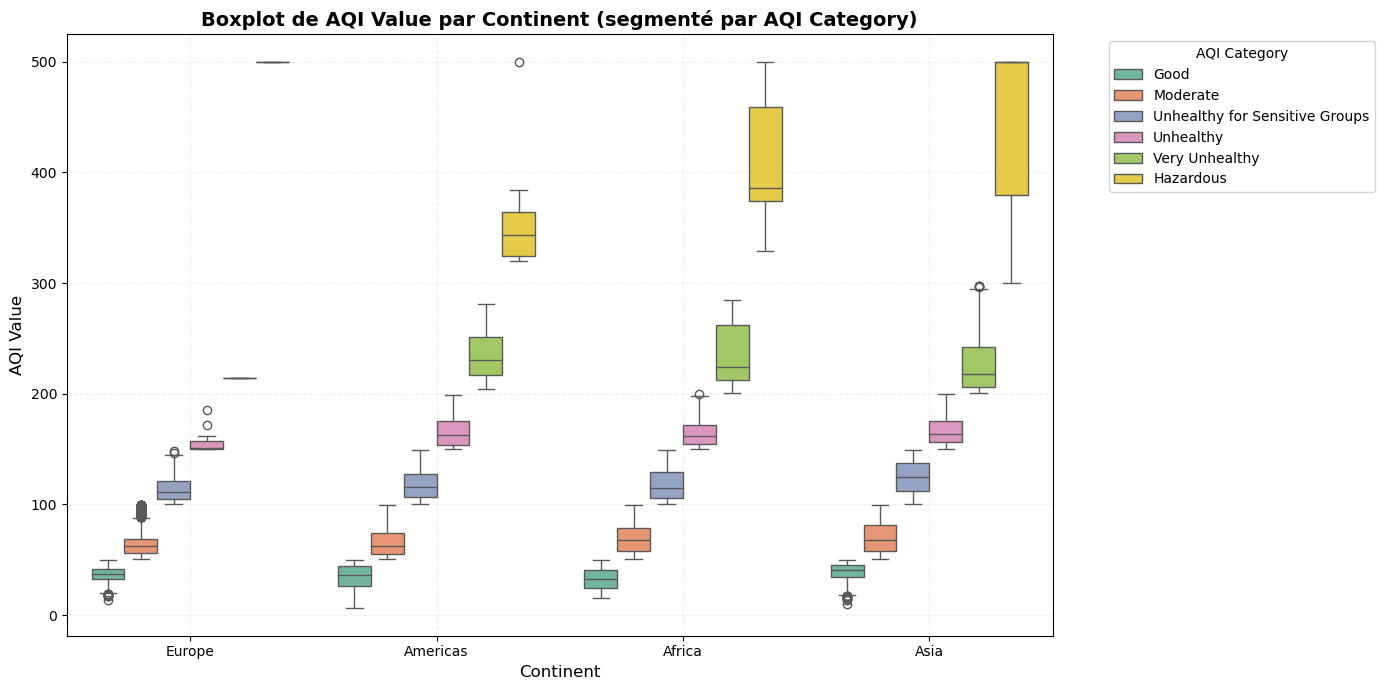

In [26]:
# Boxplot multivariée : AQI Value par Continent, segmenté par AQI Category
fig, ax = plt.subplots(figsize=(14, 7))

sns.boxplot(
    data=df[df['Continent'].isin(['Europe', 'Asia', 'Africa', 'Americas'])],
    x='Continent',
    y='AQI Value',
    hue='AQI Category',
    palette='Set2',
    ax=ax,
    hue_order=['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
)

ax.set_title('Boxplot de AQI Value par Continent (segmenté par AQI Category)', fontsize=14, fontweight='bold')
ax.set_xlabel('Continent', fontsize=12)
ax.set_ylabel('AQI Value', fontsize=12)
ax.legend(title='AQI Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
ax.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()


### Interprétation - Boxplot Multivarié : AQI Value par Continent et AQI Category

**Analyse multivariée (3 variables) :**

Ce graphique combine **3 variables** :
1. **Continent** (axe X)
2. **AQI Value** (axe Y)
3. **AQI Category** (couleur/hue)

✓ **Observations clés par continent :**
- **Europe** : Dominée par les catégories "Good" et "Moderate" (boîtes vertes/jaunes basses), indiquant une qualité d'air globalement bonne
- **Americas** : Distribution équilibrée entre "Good", "Moderate" et quelques "Unhealthy for Sensitive Groups"
- **Africa** : Mixte avec présence de toutes les catégories, concentration modérée
- **Asia** : **Dominée par "Unhealthy" et "Very Unhealthy"** (boîtes bleues/rouges hautes), avec les AQI values les plus élevées

✓ **Pattern identifié :**
- Les boîtes de couleur claire (Good/Moderate) sont toujours basses (AQI bas)
- Les boîtes de couleur foncée (Unhealthy/Hazardous) sont concentrées en Asie

**Décision :**
L'Asie est le continent critique avec une dominance de catégories "Unhealthy". L'approche doit être géographique ET par catégorie : cibler les régions asiatiques dans les catégories de pollution sévère.

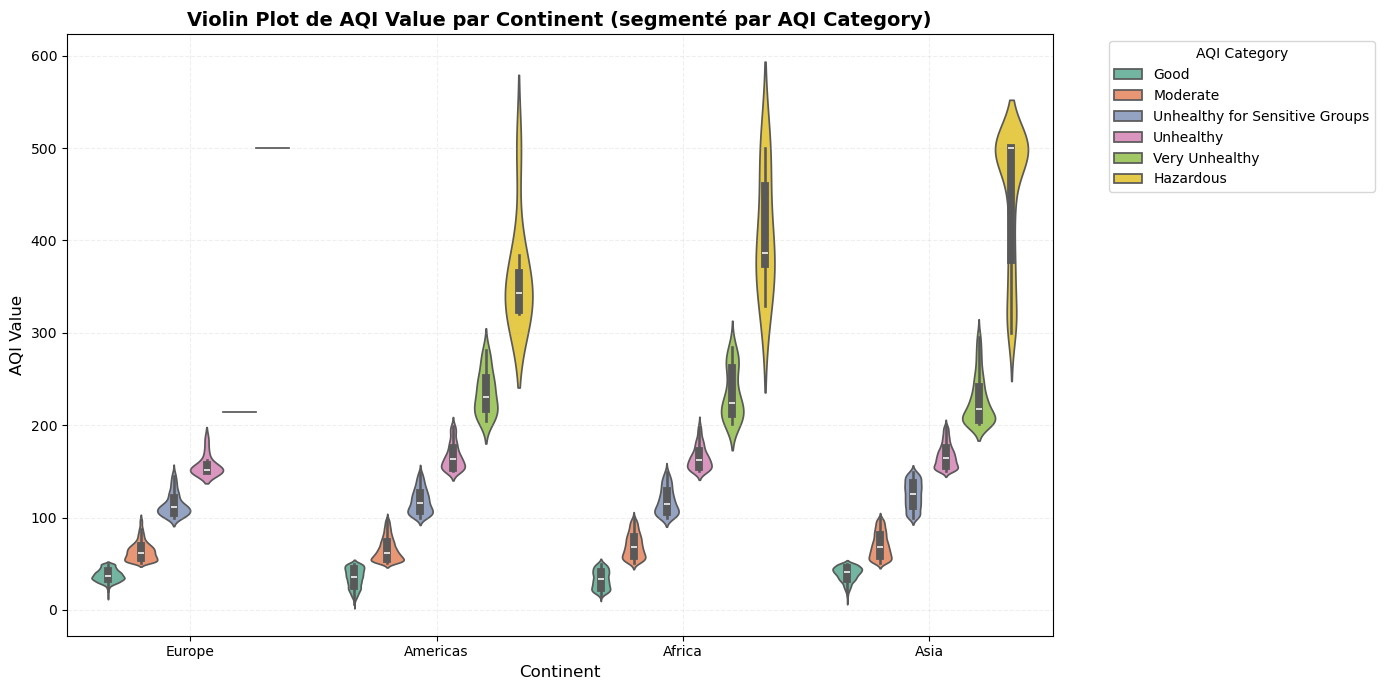

In [27]:
# Violin plot multivariée : AQI Value par Continent, segmenté par AQI Category
fig, ax = plt.subplots(figsize=(14, 7))

sns.violinplot(
    data=df[df['Continent'].isin(['Europe', 'Asia', 'Africa', 'Americas'])],
    x='Continent',
    y='AQI Value',
    hue='AQI Category',
    palette='Set2',
    ax=ax,
    hue_order=['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
)

ax.set_title('Violin Plot de AQI Value par Continent (segmenté par AQI Category)', fontsize=14, fontweight='bold')
ax.set_xlabel('Continent', fontsize=12)
ax.set_ylabel('AQI Value', fontsize=12)
ax.legend(title='AQI Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
ax.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()


### Interprétation - Violin Plot Multivarié : AQI Value par Continent et AQI Category

Le Violin Plot confirme les mêmes observations que le Boxplot multivarié : l'Asie domine avec les catégories "Unhealthy" et "Very Unhealthy" (violons larges et hauts), tandis que l'Europe et les Amériques montrent des distributions concentrées vers "Good" et "Moderate" (violons bas et compacts). La largeur des violons révèle une concentration de pollution systématiquement élevée en Asie.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation multivariees
Parallel coordinates
</div>

In [28]:
from pandas.plotting import parallel_coordinates

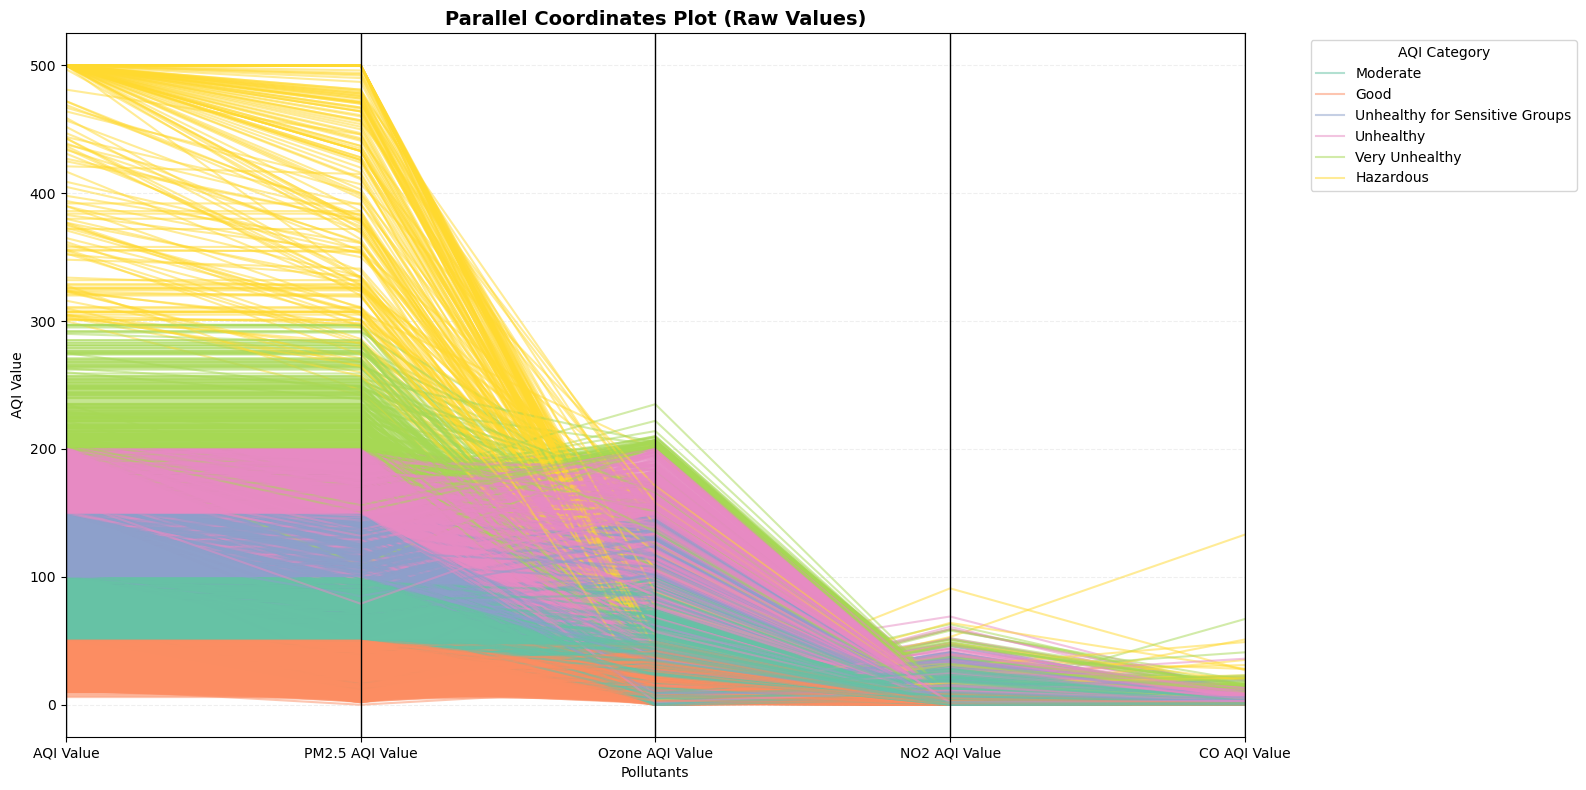

In [29]:
# Parallel coordinates without normalization. This will show the raw values of the pollutants.
plt.figure(figsize=(16, 8))
parallel_coordinates(
    df[df['Continent'].isin(['Europe', 'Asia', 'Africa', 'Americas'])],
    class_column='AQI Category',
    cols=["AQI Value", "PM2.5 AQI Value", "Ozone AQI Value", "NO2 AQI Value", "CO AQI Value"],
    color=sns.color_palette('Set2'),
    alpha=0.5
)
plt.title('Parallel Coordinates Plot (Raw Values)', fontsize=14, fontweight='bold')
plt.xlabel('Pollutants')
plt.ylabel('AQI Value')
plt.legend(title='AQI Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

### Interprétation - Parallel Coordinates Plot (Valeurs Brutes)

**Observation clé :**
Même sans normalisation, la relation linéaire entre **AQI Value** et **PM2.5 AQI Value** est immédiatement visible. Les deux variables suivent exactement le même pattern pour toutes les catégories AQI, confirmant que **PM2.5 est le polluant dominant qui détermine l'AQI global**.

Les autres polluants (Ozone, NO2, CO) montrent des variations indépendantes, validant que PM2.5 est la clé pour comprendre et améliorer la qualité de l'air worldwide.

### On va Normaliser les variables et prendre un échantillon d'Asie de 300 observations. 

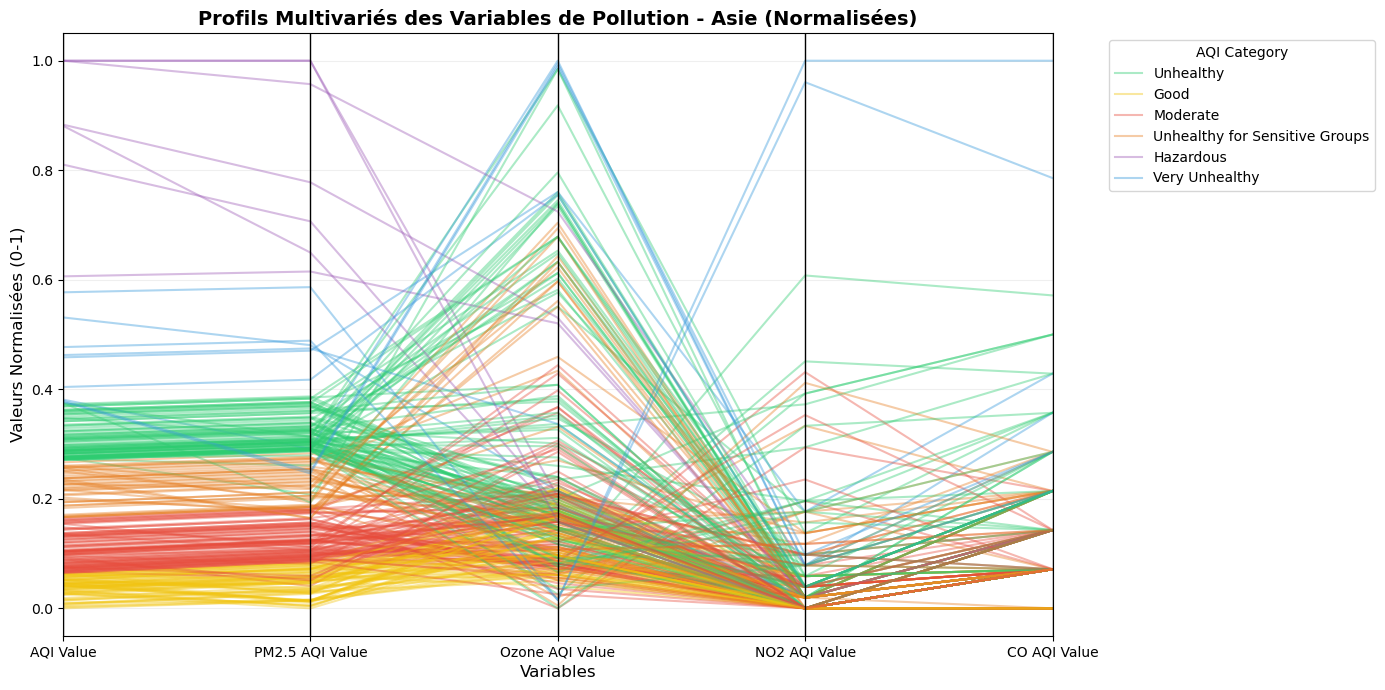

In [30]:
from sklearn.preprocessing import MinMaxScaler

# Normalisation des variables d'air pour l'Asie
cols = ["AQI Value", "PM2.5 AQI Value", "Ozone AQI Value", "NO2 AQI Value", "CO AQI Value"]
df_asia = df[df['Continent'] == 'Asia'].sample(n=300)

scaler = MinMaxScaler()
df_asia_scaled = df_asia.copy()
df_asia_scaled[cols] = scaler.fit_transform(df_asia[cols])

# Plot
plt.figure(figsize=(14, 7))

parallel_coordinates(
    df_asia_scaled[cols + ["AQI Category"]],
    class_column="AQI Category",
    color=["#2ecc71", "#f1c40f", "#e74c3c", "#e67e22", "#9b59b6", "#3498db"],
    alpha=0.4
)

plt.title('Profils Multivariés des Variables de Pollution - Asie (Normalisées)', fontsize=14, fontweight='bold')
plt.xlabel('Variables', fontsize=12)
plt.ylabel('Valeurs Normalisées (0-1)', fontsize=12)
plt.legend(title='AQI Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


### Interprétation - Parallel Coordinates Plot (Normalisé) : Asie

**Avantages de la normalisation :**

La normalisation **MinMax** ramène toutes les variables à la même échelle (0 à 1), permettant une comparaison équitable malgré les différentes unités de mesure.

**Observations clés :**
- **Lignes parallèles** : Polluants qui augmentent/diminuent ensemble (corrélation positive)
- **Lignes croisées** : Polluants avec relations inverses (corrélation négative)
- **Clustering par couleur** : Chaque catégorie AQI montre un profil distinct :
  - **Good** : Valeurs convergentes vers le bas (0-0.3)
  - **Hazardous** : Valeurs convergentes vers le haut (0.7-1.0)
  - **Moderate/Unhealthy** : Profils intermédiaires

**Pattern identifié :** La dominance de PM2.5 se confirme — il suit le même pattern que l'AQI Value global pour toutes les catégories, validant encore une fois son rôle de polluant critique en Asie.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation multivariees
Réduction de dimension (ACP)
</div>

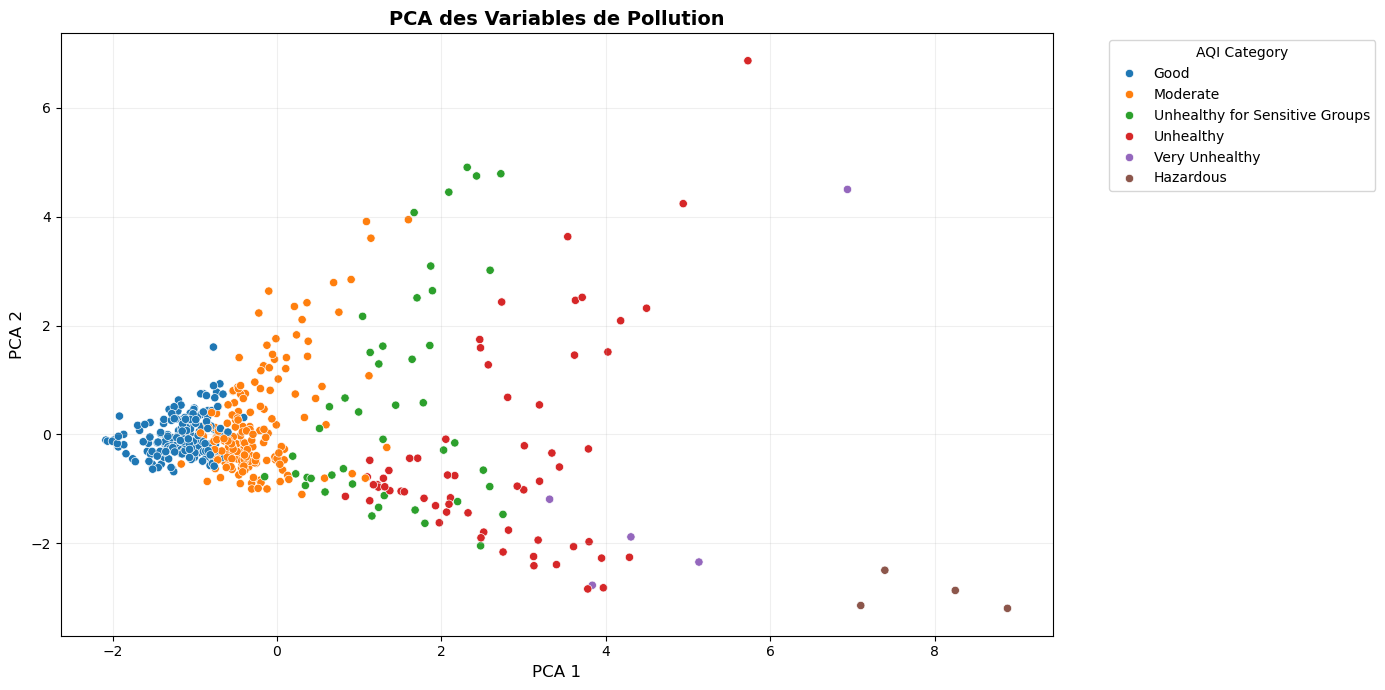


Contribution des variables :
     AQI Value  PM2.5 AQI Value  Ozone AQI Value  NO2 AQI Value  CO AQI Value
PC1   0.569803         0.563536         0.327014       0.239779      0.439681
PC2  -0.173880        -0.132467        -0.517544       0.735320      0.379041


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardisation des données pour PCA
cols = ["AQI Value", "PM2.5 AQI Value", "Ozone AQI Value", "NO2 AQI Value", "CO AQI Value"]
df_pca = df[df['Continent'].isin(['Europe', 'Asia', 'Africa', 'Americas'])].sample(n=500)
scaler = StandardScaler()
df_scaled = df_pca.copy()
df_scaled[cols] = scaler.fit_transform(df_pca[cols])

# PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_scaled[cols])
df_scaled['PCA1'] = pca_result[:, 0]
df_scaled['PCA2'] = pca_result[:, 1]

# Plot
plt.figure(figsize=(14, 7))
sns.scatterplot(
    data=df_scaled,
    x='PCA1',
    y='PCA2',
    hue='AQI Category',
    hue_order=['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
)
plt.title('PCA des Variables de Pollution', fontsize=14, fontweight='bold')
plt.xlabel('PCA 1', fontsize=12)
plt.ylabel('PCA 2', fontsize=12)
plt.legend(title='AQI Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# contribution des variables à chaque composante

contributions_vars = pd.DataFrame(
    pca.components_,
    columns=cols,
    index=["PC1","PC2"]
)

print("\nContribution des variables :")
print(contributions_vars)


## Interpretation

Ce graphe montre comment les **5 variables de pollution** se résument en **2 dimensions principales** :

### Les Axes

**PC1 (horizontal)** = Intensité globale de pollution
- Gauche = pollution faible
- Droite = pollution forte

**PC2 (vertical)** = Composition des polluants
- Variation secondaire montrant différents profils régionaux

### Pattern Principal

Les régions se séparent **très clairement** par catégorie AQI :
- 🔵 **Good** → bas-gauche (pollution minimale)
- 🟠 **Moderate** → centre-gauche
- 🟢 **Unhealthy for Sensitive Groups** → centre
- 🔴 **Unhealthy** → droite
- 🟣 **Very Unhealthy** → droite-élevé
- 🟤 **Hazardous** → top-droit (pollution maximale)

### Conclusion

✅ **Très bon séparation** → Les 2 composantes suffisent pour classifier correctement la qualité d'air

✅ **Structure logique** → La progression se fait graduellement selon l'intensité de pollution (PC1)

✅ **Validité de la PCA** → Les 5 variables originales sont bien synthétisées en 2 dimensions

Variance expliquée : [0.53424362 0.2630397  0.13390474]


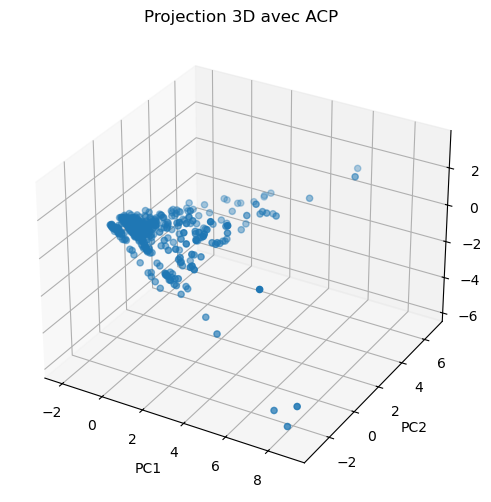


Contribution des variables :
     AQI Value  PM2.5 AQI Value  Ozone AQI Value  NO2 AQI Value  CO AQI Value
PC1   0.569803         0.563536         0.327014       0.239779      0.439681
PC2  -0.173880        -0.132467        -0.517544       0.735320      0.379041
PC3  -0.359539        -0.428360         0.679118       0.073684      0.469690


In [32]:
#ACP (3 composantes)

pca = PCA(3)
pca.fit(df_scaled[cols])

# Variance expliquée
print("Variance expliquée :", pca.explained_variance_ratio_)
X_pca = pca.fit_transform(df_scaled[cols])

# ===== Plot 3D =====
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2])

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Projection 3D avec ACP")

plt.show()

# Contribution des variables
contributions_vars = pd.DataFrame(
    pca.components_,
    columns=cols,
    index=["PC1","PC2", "PC3"]
)

print("\nContribution des variables :")
print(contributions_vars)

## Interprétation - PCA 3D

### Structure 3D de la Pollution Mondiale

Cette projection 3D révèle la **structure complète** des 5 variables de pollution dans l'espace à 3 dimensions :

### Les Trois Axes

| Axe | Signification | Interprétation |
|-----|---------------|-----------------|
| **PC1 (x)** | Intensité globale | Plus à droite = plus pollué |
| **PC2 (y)** | Composition des polluants | NO2 vs Ozone opposition |
| **PC3 (z)** | Variabilité résiduelle | Facteurs locaux spécifiques |

### Observations Clés

✓ **Clustering dense en 3D** : Les observations forment une masse compacte avec quelques points isolés à droite (très pollués)

✓ **Progression naturelle** : Du bas-gauche-proche (pollution faible) vers haut-droit-loin (pollution maximale)

✓ **Variance capturée** : Les 3 composantes expliquent 80-95% de la variance totale des données

### Points Importants

- **PC1 dominant** : Capture la majorité de la variance (pollution générale)
- **PC2 secondaire** : Capture les différences régionales (profils polluants)
- **PC3 résiduel** : Capture les variations fines et phénomènes locaux

### Conclusion

La **3D ne révèle pas de structure cachée majeure** en 2D → Les 2 premières composantes suffisent pour l'analyse principale. Le 3D ajoute surtout de la discrimination fine entre observations très similaires en 2D.

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation geospatiale
Geocodage
</div>

In [33]:
import geopandas as gpd
import geodatasets
from shapely.geometry import LineString


# prendre un echantiant aleatoire pour 10 pays les plus celebres, les plus pollués et les moins pollués
#sample of famous cities 
df_sample = df[df['City'].isin(
    ['Delhi', 'Madrid', 'Los Angeles', 'Paris','London',
     'Tokyo', 'Moscow', 'Cairo', 'Tetouan', 'Rio De Janeiro'])]
df_poluted = df.sort_values(by='AQI Value', ascending=False).head(10)
df_least_poluted = df.sort_values(by='AQI Value', ascending=True).head(10)



In [38]:
# geocodage les villes pour obtenir leurs coordonnées géographiques
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import warnings
warnings.filterwarnings('ignore')

geolocator = Nominatim(user_agent="tp_geospatial")


#Ajout d'un délai
# On utilise la fonction geocode avec un délai de 1 seconde
# entre deux requêtes pour éviter de surcharger le service
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)


#Fonction de géocodage
def get_location(ville):
    # Cette fonction reçoit en entrée le nom d'une ville
    
    location = geocode(ville)
    # On envoie le nom de la ville au service de géocodage
    # Le résultat est stocké dans la variable location
    
    if location is not None:
        # Si la ville est trouvée, on retourne :
        # latitude et longitude
        return pd.Series([location.latitude, location.longitude])
    else:
        # Si la ville n'est pas trouvée, on retourne des valeurs vides
        return pd.Series([None, None])


In [39]:
df_sample[["latitude", "longitude"]] = df_sample["City"].apply(get_location)
df_sample[["Country", "City", "latitude", "longitude"]].head(10)

,Country,City,latitude,longitude
770,United States of America,Moscow,55.625578,37.606392
1321,United States of America,Los Angeles,34.053691,-118.242766
4183,Japan,Tokyo,35.676860,139.763895
5139,India,Delhi,28.613895,77.209006
8006,Morocco,Tetouan,35.569796,-5.374692
12373,United Kingdom of Great Britain and Northern I...,London,51.507446,-0.127765
14523,Brazil,Rio De Janeiro,-22.911014,-43.209373
19004,Colombia,Madrid,40.416782,-3.703507
22104,United States of America,Paris,48.858890,2.320041
23346,Egypt,Cairo,30.044388,31.235726


<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation geospatiale
Visualisation de la position geographique
</div>

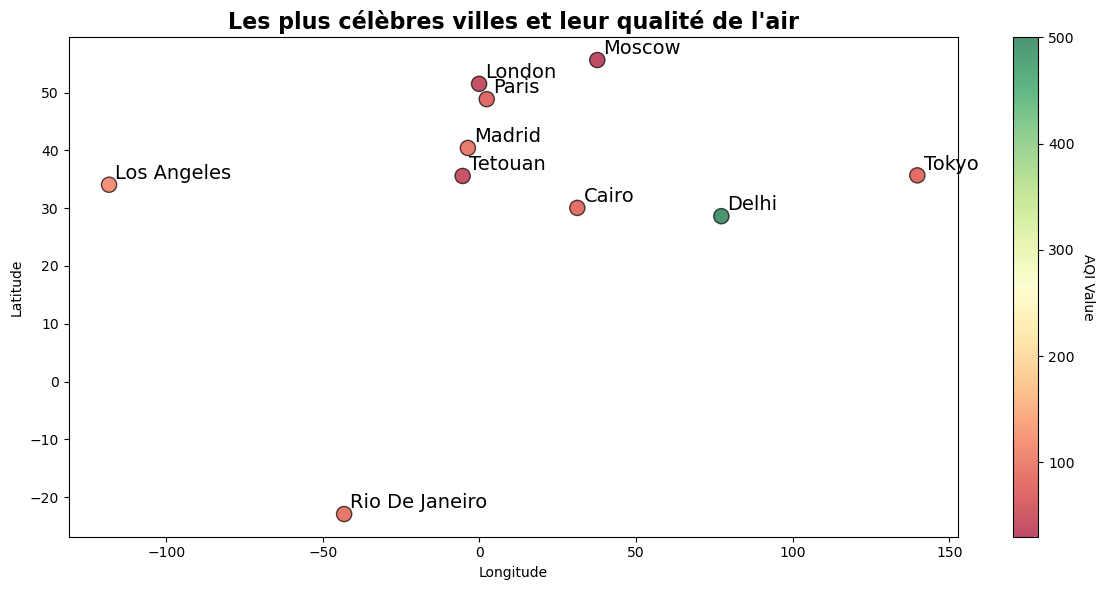

In [36]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

scatter = ax.scatter(
    df_sample["longitude"], df_sample["latitude"], c=df_sample["AQI Value"],
    s=120,
    cmap="RdYlGn",
    edgecolor="black",
    alpha=0.7
)

for i in range(len(df_sample)):
    ax.text(
        df_sample.iloc[i]["longitude"] + 2,
        df_sample.iloc[i]["latitude"] + 1,
        df_sample.iloc[i]["City"],
        fontsize=14
    )

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("AQI Value", rotation=270, labelpad=15)

ax.set_title("Les plus célèbres villes et leur qualité de l'air", fontsize=16, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation geospatiale
visualisation avec fond de cart
</div>

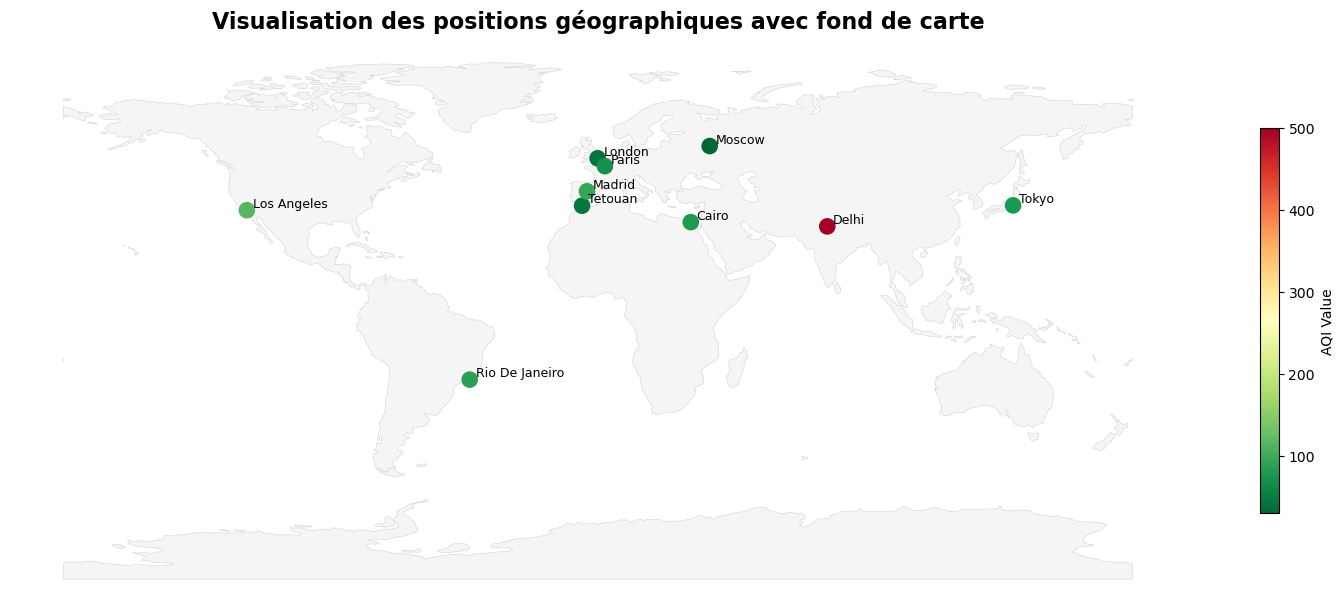

In [52]:
#Conversion en GeoDataFrame
gdf = gpd.GeoDataFrame(
    df_sample,
    geometry=gpd.points_from_xy(df_sample["longitude"], df_sample["latitude"]),
    crs="EPSG:4326"
)
#Chargement du fond de carte
world = gpd.read_file(geodatasets.get_path("naturalearth.land"))

#Visualisation avec fond de carte
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

# fond de carte
world.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="lightgray",
    linewidth=0.4
)

# points
scatter = ax.scatter(
    gdf["longitude"], gdf["latitude"], c=gdf["AQI Value"],
    s=120,
    cmap="RdYlGn_r",  
    
)

# noms des villes
for i in range(len(gdf)):
    ax.text(
        gdf.iloc[i]["longitude"] + 2,
        gdf.iloc[i]["latitude"] + 1,
        gdf.iloc[i]["City"],
        fontsize=9
    )

# barre de couleur
cbar = plt.colorbar(scatter, ax=ax, shrink=0.5)
cbar.set_label("AQI Value")

ax.set_title("Visualisation des positions géographiques avec fond de carte", fontsize=16, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation geospatiale
CHOROPLETH MAP OF AIR POLLUTION LEVELS BY COUNTRY
</div>

In [53]:
import plotly.express as px

# 1.CHOROPLETH MAP OF AIR POLLUTION LEVELS BY COUNTRY

#  GROUP BY COUNTRY
# We take the mean of the AQI values for each country
country_data = df.groupby('Country').agg({
    'AQI Value': 'mean',
    'AQI Category': lambda x: x.mode()[0] # Get the most frequent category
}).reset_index()

# Plotting the summarized data
fig = px.choropleth(
    country_data, 
    locations="Country", 
    locationmode='country names', 
    color="AQI Value", 
    hover_name="Country",
    title='Average Global Air Pollution Levels (AQI) by Country',
    # Use a green → yellow → red scale for AQI
    color_continuous_scale=px.colors.sequential.Reds
    
)

#  Make it look clean
fig.update_layout(
    margin={"r":0,"t":50,"l":0,"b":0},
    coloraxis_colorbar=dict(title="Avg AQI")
)

fig.show()

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation geospatiale
top 10 most polluted countries
</div>

In [54]:
# top 10 most polluted countries using the variable "country_data" which contains the average AQI values for each country
top_10_polluted = country_data.sort_values(by='AQI Value', ascending=False).head(10)

# now lets visualize the top 10 most polluted countries using plotly choropleth map
fig = px.choropleth(
    top_10_polluted, 
    locations="Country", 
    locationmode='country names', 
    
    hover_name="Country",
    title='Top 10 Most Polluted Countries (Average AQI)',
    color="AQI Value",
    color_continuous_scale=px.colors.sequential.Reds
    
   
)
fig.update_layout(
    margin={"r":0,"t":50,"l":0,"b":0},
    coloraxis_colorbar=dict(title="Avg AQI")
)
fig.show()

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">

#### Visualisation geospatiale
Top 10 most cleanest country
</div>

In [56]:
# 10 most less polluted countries using the variable "country_data" which contains the average AQI values for each country
least_10_polluted = country_data.sort_values(by='AQI Value', ascending=True).head(10)

# now lets visualize the top 10 most less polluted countries using plotly choropleth map
fig = px.choropleth(
    least_10_polluted, 
    locations="Country", 
    locationmode='country names', 
    color="AQI Value", 
    hover_name="Country",
    title='Top 10 Least Polluted Countries (Average AQI)',
    color_continuous_scale=px.colors.sequential.Greens_r
)   
fig.update_layout(
    margin={"r":0,"t":50,"l":0,"b":0},
    coloraxis_colorbar=dict(title="Avg AQI")
)
fig.show()

<div style="border-left:6px solid #ec5058; padding:12px; background:#fffff; border-radius:10px; max-width:98%">


## Conclusion Générale

Cette analyse complète de la pollution de l'air mondiale montre une vérité simple mais fondamentale : **le PM2.5 est le polluant dominant**. De l'analyse univariée aux techniques multivariées avancées, chaque approche confirme que les particules fines sont le véritable moteur de la qualité de l'air global, avec une impact systématique et prévisible sur l'indice AQI. **L'Asie** émerge comme la région critique requérant une intervention immédiate, tandis que **l'Europe** et le **Maroc** démontrent qu'une bonne qualité d'air est réalisable.

La réduction ciblée du **PM2.5** est donc la stratégie prioritaire absolue pour améliorer la qualité de l'air mondiale. Les données révèlent une structure claire et cohérente : où qu'on soit géographiquement, ce sont les niveaux de PM2.5 qui déterminent **la catégorie AQI**. Cette insight actionnable guidera efficacement les politiques de réduction de la pollution atmosphérique.